In [ ]:
# Replace this code if using some other method to load the file

from google.colab import drive
drive.mount('/content/drive')

# Change file path depending on the location of the data
path = "/content/drive/MyDrive/warehouse-bottleneck-analyzer/data/raw/warehouse_line_throughput_synthetic.csv"

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Read the file, ensure "timestamp" is in date-time format
# then set it as the index.

df = pd.read_csv(path)
df["timestamp"] = pd.to_datetime(df["timestamp"])
df = df.sort_values("timestamp").reset_index(drop=True)
df = df.set_index("timestamp")


*There will be analyses on effects of different sets of features, (1) Containing engineered features; (2) containing two sets of features; (3) containing a full feature set.*

In [ ]:
# Engineered features
df["capacity_gap"] = (df["available_work"] - df["line_capacity"])
df["work_pressure"] = df["available_work"] / (df["line_capacity"] + 1)
df["backlog_planned_ratio"] = (df["backlog_units"] / df["planned_work"])

# Print a few records and verify values of engineered features
print(df[[
    "available_work",
    "line_capacity",
    "capacity_gap",
    "work_pressure"
]].head())


                     available_work  line_capacity  capacity_gap  \
timestamp                                                          
2026-04-01 00:00:00             893            820            73   
2026-04-01 01:00:00             844            840             4   
2026-04-01 02:00:00             732            664            68   
2026-04-01 03:00:00            1013            728           285   
2026-04-01 04:00:00            1004            560           444   

                     work_pressure  
timestamp                           
2026-04-01 00:00:00       1.087698  
2026-04-01 01:00:00       1.003567  
2026-04-01 02:00:00       1.100752  
2026-04-01 03:00:00       1.389575  
2026-04-01 04:00:00       1.789661  


In [ ]:
# Is the capacity deficit sufficient by itself?
cap_gap_feature_cols = [
    "capacity_gap"
]

# Does explicit staffing add information?
cap_gap_packer_feature_cols = [
    "capacity_gap",
    "packers_assigned"
]

# Does normalized workload pressure add information?
cap_gap_wp_feature_cols = [
    "capacity_gap",
    "work_pressure"
]

# Does relative backlog add information?
cap_gap_bpr_feature_cols = [
    "capacity_gap",
    "backlog_planned_ratio"
]

# Create sets of features to train and compare models
full_engineered_features = [
    "backlog_planned_ratio",
    "capacity_gap",
    "work_pressure"
]

# Full set of trial features
cap_gap_bpr_wp_packer_feature_cols = [
    "work_pressure",
    "packers_assigned",
    "capacity_gap",
    "backlog_planned_ratio"
]

# Not used at the time of the last run but is available if needed
#full_features = [
#    "hour",
#    "stations_down",
#    "active_stations",
#    "packers_scheduled",
#    "packers_available",
#    "packers_available_after_support",
#    "added_packers",
#    "packers_assigned",
#    "reassigned_packers",
#    "avg_units_per_packer",
#    "planned_work",
#    "work_diverted_out",
#    "net_incoming_volume",
#    "units_packed",
#    "available_work",
#    "backlog_units",
#    "capacity_shortfall",
#    "utilization_rate",
#    "bottleneck_flag",
#    "work_pressure",
#    "backlog_planned_ratio",
#    "capacity_gap",
#    "backlog_lag_1",
#    "backlog_lag_2",
#    "capacity_gap_lag_1",
#    "backlog_change"
#]


*At one point I received a singular matrix error when trying to use Logistic Regression. As I created engineered features that were mathematically related, I used Singular Value Decomposition (SVD). SVD is a diagnostic tool that tells you whether your feature set contains redundant information and whether the model will have trouble estimating coefficients reliably, even if the features may have little or moderate correlation. This could lead to large standard errors, sign changes in coefficients, and odds ratios that are difficult to interpret.*
*Additionally, condition numbers generated by SVD will help show how numerically stable the feature set is. Large condition numbers aren't as stable as smaller condition numbers.*

*After viewing the results, and knowing the operational reason behind the features, I concluded a couple of features were not needed. After removing them and running subsequent SVD analyses showed a substantial improvement in numerical stability, by reducing the condition number from approximately 2,041 to 371.*

*SVD is not necessary for other types of analysis tools like Random Forest or XGBoost as they don't estimate coefficients.*

In [ ]:
# The Condition number for the engineered feature set is astronomical and should
# not be used. Both Expanded feature sets V1.0 and V2.0 are still high. Efforts
# should be made to find sets with better results, and therefore be more stable.

import statsmodels.api as sm
from sklearn.preprocessing import StandardScaler

X_engineered = df[full_engineered_features]
X_eng_scaled = StandardScaler().fit_transform(X_engineered)

u, s, vh = np.linalg.svd(
    X_eng_scaled,
    full_matrices=False
)

smallest_vector = vh[-1]

svd_diagnostic = pd.DataFrame({
    "feature": full_engineered_features,
    "loading": smallest_vector,
    "abs_loading": np.abs(smallest_vector)
}).sort_values("abs_loading", ascending=False)

print("Singular values:")
print(s)

print("\nCondition number:")
print(s.max() / s.min())

print("\nSmallest singular-vector loadings:")
print(svd_diagnostic)
print()

X_cap_gap_feature_cols = df[cap_gap_feature_cols]
X_cap_gap_scaled = StandardScaler().fit_transform(X_cap_gap_feature_cols)

u, s, vh = np.linalg.svd(X_cap_gap_scaled)

print("Singular values for feature set with Capacity only:")
print(s)

print("\nCondition number for feature set with Capacity only:")
print(np.linalg.cond(X_cap_gap_scaled))
print()

X_cap_gap_packer_feature_cols = df[cap_gap_packer_feature_cols]
X_cap_gap_packer_scaled = StandardScaler().fit_transform(X_cap_gap_packer_feature_cols)

u, s, vh = np.linalg.svd(X_cap_gap_packer_scaled)

print("Singular values for feature set Capacity with Packers Assigned:")
print(s)

print("\nCondition number for feature set Capacity with Packers Assigned:")
print(np.linalg.cond(X_cap_gap_packer_scaled))
print()

X_cap_gap_wp_feature_cols = df[cap_gap_wp_feature_cols]
X_cap_gap_wp_scaled = StandardScaler().fit_transform(X_cap_gap_wp_feature_cols)

u, s, vh = np.linalg.svd(X_cap_gap_wp_scaled)

print("Singular values for feature set V3:")
print(s)

print("\nCondition number for feature set V3:")
print(np.linalg.cond(X_cap_gap_wp_scaled))
print()

X_cap_gap_bpr_feature_cols = df[cap_gap_bpr_feature_cols]
X_cap_gap_bpr_scaled = StandardScaler().fit_transform(X_cap_gap_bpr_feature_cols)

u, s, vh = np.linalg.svd(X_cap_gap_bpr_scaled)

print("Singular values for feature set V4:")
print(s)

print("\nCondition number for feature set V4:")
print(np.linalg.cond(X_cap_gap_bpr_scaled))
print()

X_cap_gap_bpr_wp_packer_feature_cols = df[cap_gap_bpr_wp_packer_feature_cols]
X_cap_gap_bpr_wp_packer_scaled = StandardScaler().fit_transform(X_cap_gap_bpr_wp_packer_feature_cols)

u, s, vh = np.linalg.svd(X_cap_gap_bpr_wp_packer_scaled)

print("Singular values for feature set V5:")
print(s)

print("\nCondition number for feature set V5:")
print(np.linalg.cond(X_cap_gap_bpr_wp_packer_scaled))
print()

Singular values:
[78.38069467 14.48259476 11.12300102]

Condition number:
7.046721880369028

Smallest singular-vector loadings:
                 feature   loading  abs_loading
2          work_pressure -0.763035     0.763035
0  backlog_planned_ratio  0.632082     0.632082
1           capacity_gap  0.135092     0.135092

Singular values for feature set with Capacity only:
[46.46504062]

Condition number for feature set with Capacity only:
1.0

Singular values for feature set Capacity with Packers Assigned:
[48.22061441 44.64047878]

Condition number for feature set Capacity with Packers Assigned:
1.080199310606244

Singular values for feature set V3:
[64.36459036 13.23629509]

Condition number for feature set V3:
4.862734620454509

Singular values for feature set V4:
[64.17795628 14.1134662 ]

Condition number for feature set V4:
4.547285220019769

Singular values for feature set V5:
[78.54994189 47.18765521 12.26309519  9.42593877]

Condition number for feature set V5:
8.333381304112962

*Correlation analysis identified moderate relationships between work diverted out, work pressure, and bottleneck conditions. Operational review indicated that work diversion was primarily a management response to workload stress rather than an independent driver of backlog risk. Consequently, the variable was removed from the explanatory feature set.*

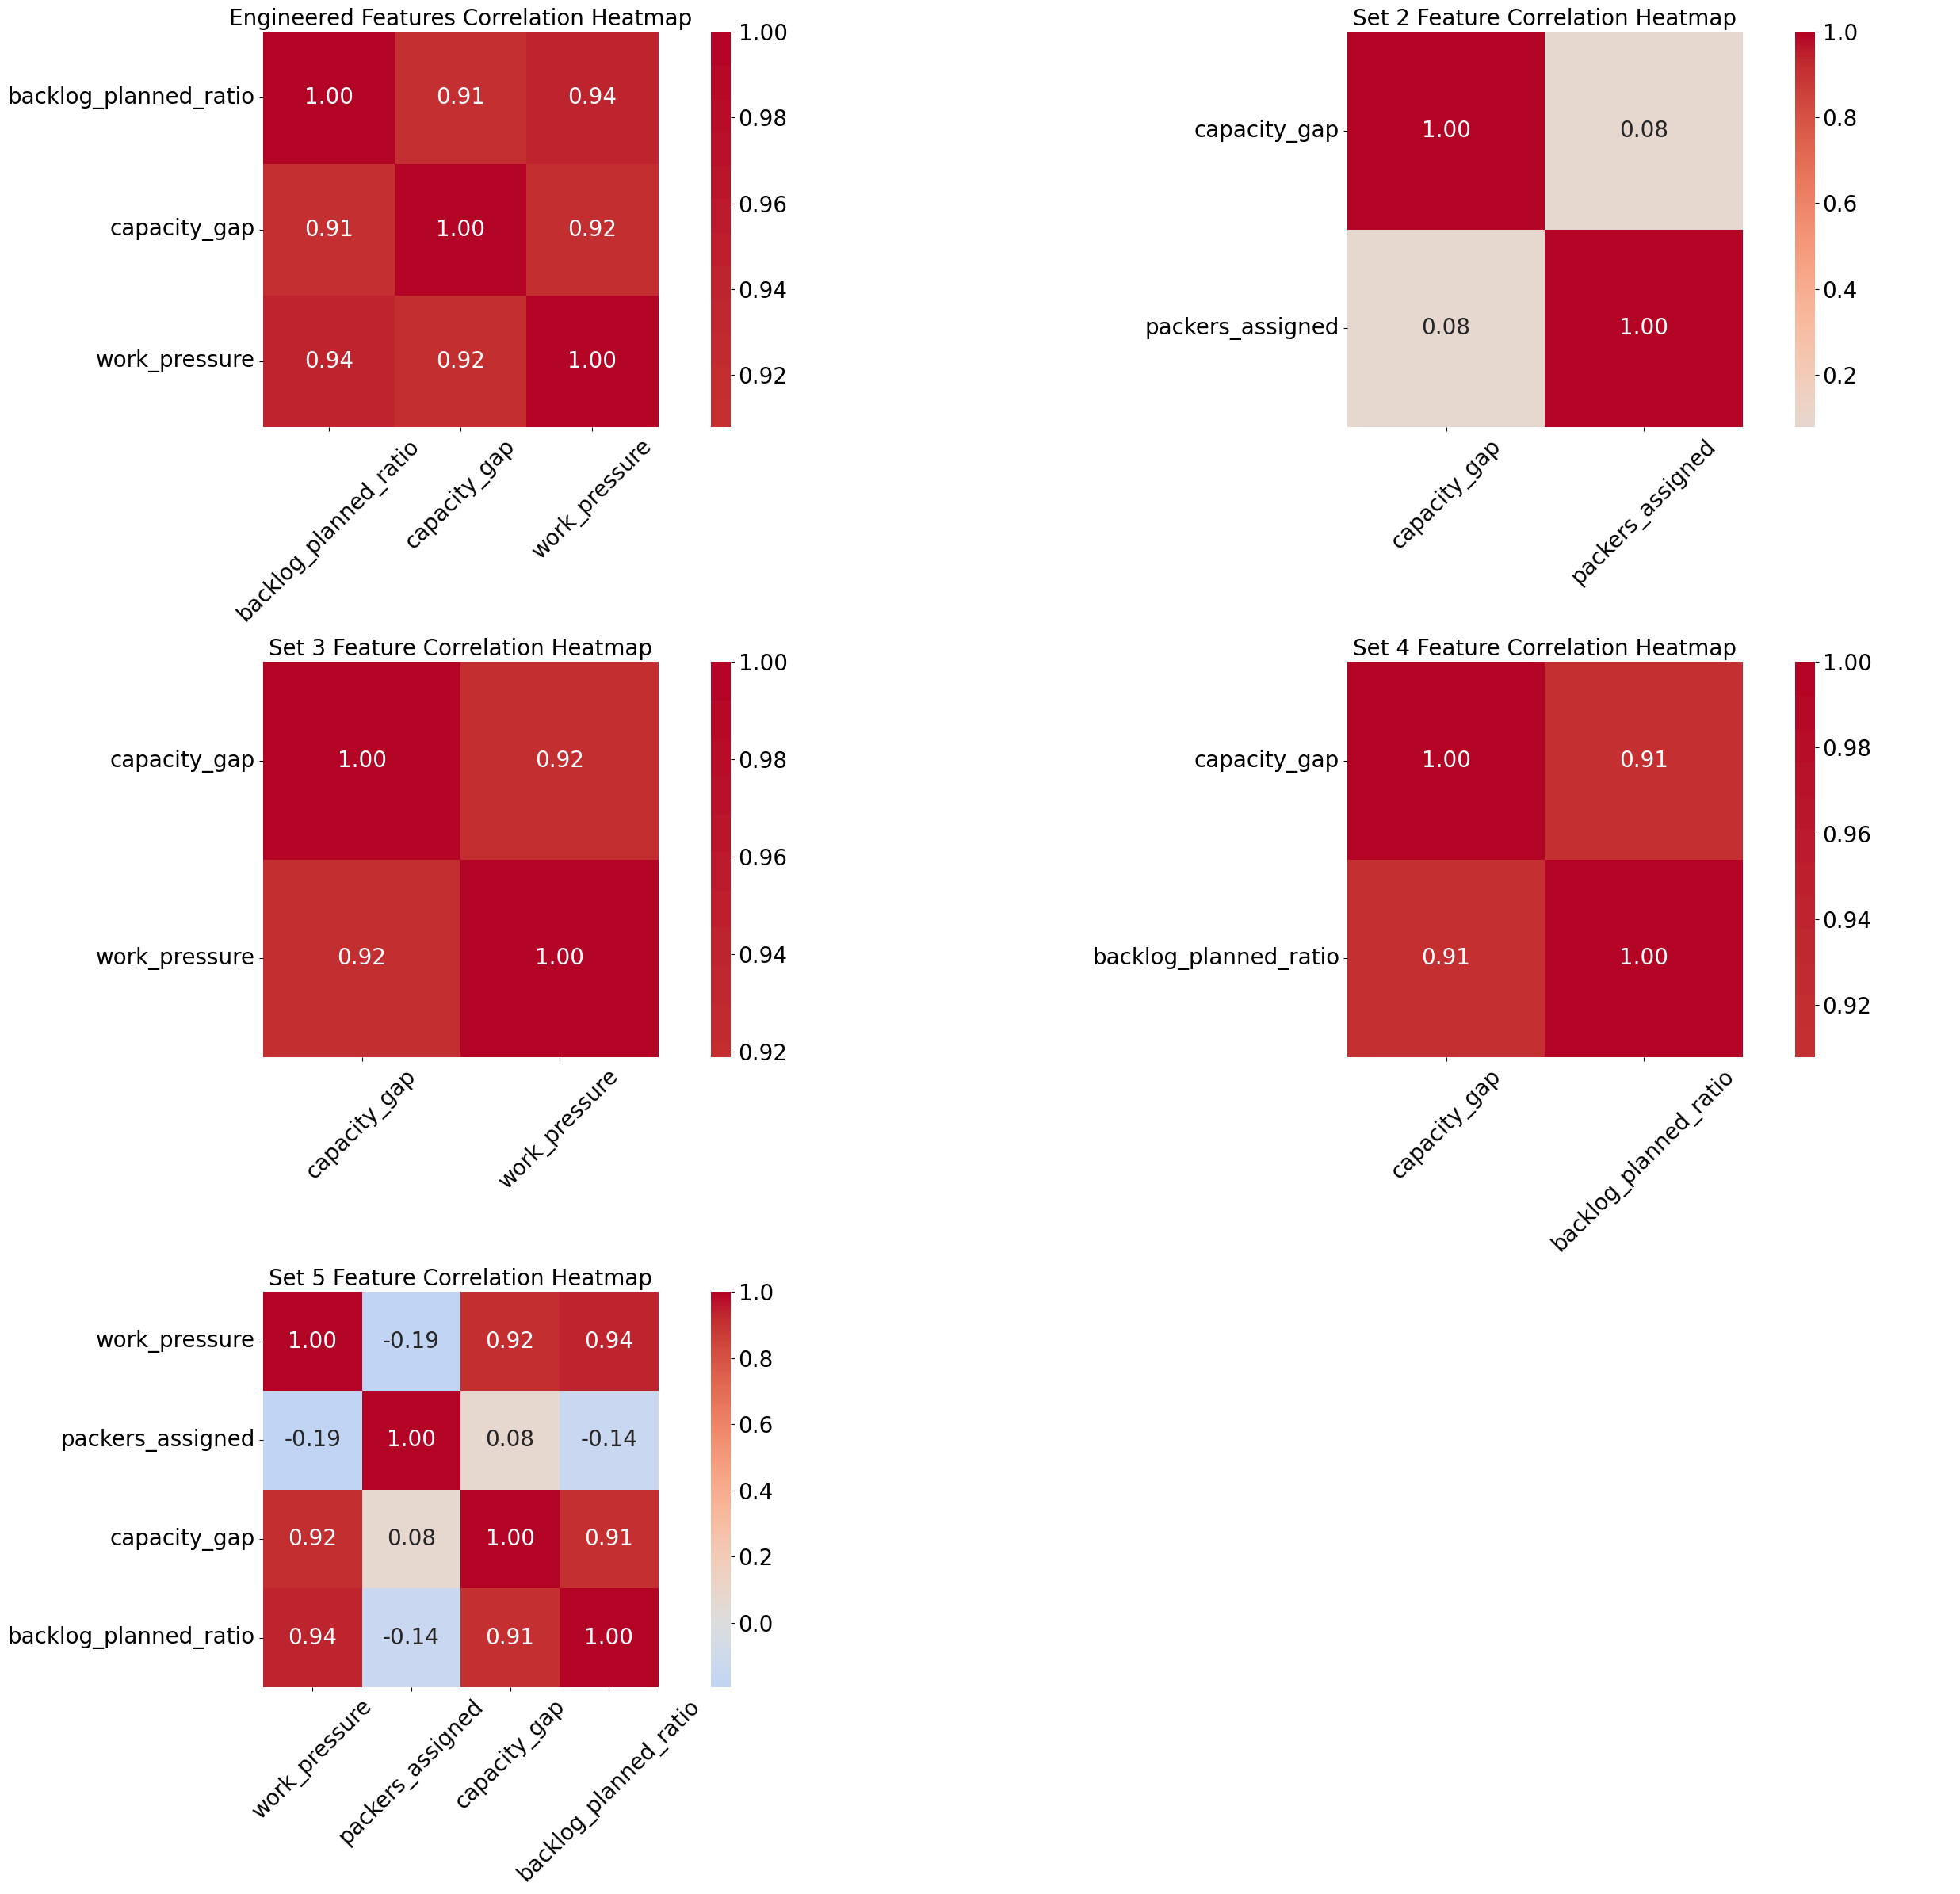

In [ ]:
corr1 = (
    df[full_engineered_features]
    .corr()
)

corr2 = (
    df[cap_gap_packer_feature_cols]
    .corr()
)

corr3 = (
    df[cap_gap_wp_feature_cols]
    .corr()
)

corr4 = (
    df[cap_gap_bpr_feature_cols]
    .corr()
)

corr5 = (
    df[cap_gap_bpr_wp_packer_feature_cols]
    .corr()
)

fig, axes = plt.subplots(
    3, 2,
    figsize=(28, 24)
)

sns.heatmap(
    corr1,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    annot_kws={"size": 20},
    ax=axes[0, 0]
)

axes[0, 0].set_title(
    "Engineered Features Correlation Heatmap",
    fontsize=20
)

sns.heatmap(
    corr2,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    annot_kws={"size": 20},
    ax=axes[0, 1]
)

axes[0, 1].set_title(
    "Set 2 Feature Correlation Heatmap",
    fontsize=20
)

sns.heatmap(
    corr3,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    annot_kws={"size": 20},
    ax=axes[1, 0]
)

axes[1, 0].set_title(
    "Set 3 Feature Correlation Heatmap",
    fontsize=20
)

sns.heatmap(
    corr4,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    annot_kws={"size": 20},
    ax=axes[1, 1]
)

axes[1, 1].set_title(
    "Set 4 Feature Correlation Heatmap",
    fontsize=20
)

sns.heatmap(
    corr5,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    annot_kws={"size": 20},
    ax=axes[2, 0]
)

axes[2, 0].set_title(
    "Set 5 Feature Correlation Heatmap",
    fontsize=20
)

axes[2, 1].axis("off")

for i in range(3):
    for j in range(2):

        for tick in axes[i, j].get_xticklabels():
            tick.set_rotation(45)
            tick.set_fontsize(20)

        for tick in axes[i, j].get_yticklabels():
            tick.set_rotation(0)
            tick.set_fontsize(20)

        # Increase colorbar number font size
        if axes[i, j].collections:
            cbar = axes[i, j].collections[0].colorbar

            if cbar is not None:
                cbar.ax.tick_params(labelsize=20)

plt.tight_layout()
plt.show()


*Having determined models look stable, I'm going to compare two different models and see which perform best. Strong tests include Log-Likelihood, AIC, BIC, and Pseudo_R2. Models could be stronger for some values, while weaker for others values, which requires determining how well they fit the business goal. I also try to prioritize values if possible, like BIC values have more emphasis, then AIC, log-likelihood, and finally Pseudo R-squared.*  

In [ ]:
y = df["next_hour_backlog_risk"]

*Attempting to perform a statsmodel logit including **bottleneck_flag** will produce a quasi-separation error. From findings above, next_hour_backlog_risk is always 0 when bottleneck_flag is 0. According to the code generating the simulated dataset, the bottleneck flag is set when capacity shortfall is above a defined threshold, in this case 200.*

*The first logit was performed as an example of this quasi-separation.*

In [ ]:
X_eng_scaled_df = pd.DataFrame(X_eng_scaled, columns=full_engineered_features, index=X_engineered.index)
X_eng_scaled_df = sm.add_constant(X_eng_scaled_df)

sm_model_engineered = sm.Logit(y, X_eng_scaled_df).fit()
print(sm_model_engineered.summary())
print()

X_cap_gap_scaled_df = pd.DataFrame(X_cap_gap_scaled, columns=cap_gap_feature_cols, index=X_cap_gap_feature_cols.index)
X_cap_gap_scaled_df = sm.add_constant(X_cap_gap_scaled_df)

sm_model_feature_v1 = sm.Logit(y, X_cap_gap_scaled_df).fit()
print(sm_model_feature_v1.summary())
print()

X_cap_gap_packer_scaled_df = pd.DataFrame(X_cap_gap_packer_scaled, columns=cap_gap_packer_feature_cols, index=X_cap_gap_packer_feature_cols.index)
X_cap_gap_packer_scaled_df = sm.add_constant(X_cap_gap_packer_scaled_df)

sm_model_feature_v2 = sm.Logit(y, X_cap_gap_packer_scaled_df).fit()
print(sm_model_feature_v2.summary())
print()

X_cap_gap_wp_scaled_df = pd.DataFrame(X_cap_gap_wp_scaled, columns=cap_gap_wp_feature_cols, index=X_cap_gap_wp_feature_cols.index)
X_cap_gap_wp_scaled_df = sm.add_constant(X_cap_gap_wp_scaled_df)

sm_model_feature_v3 = sm.Logit(y, X_cap_gap_wp_scaled_df).fit()
print(sm_model_feature_v3.summary())
print()

X_cap_gap_bpr_scaled_df = pd.DataFrame(X_cap_gap_bpr_scaled, columns=cap_gap_bpr_feature_cols, index=X_cap_gap_bpr_feature_cols.index)
X_cap_gap_bpr_scaled_df = sm.add_constant(X_cap_gap_bpr_scaled_df)

sm_model_feature_v4 = sm.Logit(y, X_cap_gap_bpr_scaled_df).fit()
print(sm_model_feature_v4.summary())
print()

X_cap_gap_bpr_wp_packer_scaled_df = pd.DataFrame(X_cap_gap_bpr_wp_packer_scaled, columns=cap_gap_bpr_wp_packer_feature_cols, index=X_cap_gap_bpr_wp_packer_feature_cols.index)
X_cap_gap_bpr_wp_packer_scaled_df = sm.add_constant(X_cap_gap_bpr_wp_packer_scaled_df)

sm_model_feature_v5 = sm.Logit(y, X_cap_gap_bpr_wp_packer_scaled_df).fit()
print(sm_model_feature_v5.summary())
print()

Optimization terminated successfully.
         Current function value: 0.265591
         Iterations 7
                             Logit Regression Results                             
Dep. Variable:     next_hour_backlog_risk   No. Observations:                 2159
Model:                              Logit   Df Residuals:                     2155
Method:                               MLE   Df Model:                            3
Date:                    Thu, 08 Oct 2026   Pseudo R-squ.:                  0.3383
Time:                            02:01:36   Log-Likelihood:                -573.41
converged:                           True   LL-Null:                       -866.55
Covariance Type:                nonrobust   LLR p-value:                9.528e-127
                            coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------
const                    -2.7367      0.112    -24.402

In [ ]:
# Create sets of features to train and compare models
eng_features_ind_1 = [
    "backlog_planned_ratio"
]
X_eng_ind_1 = df[eng_features_ind_1]
X_eng_scaled_ind_1 = StandardScaler().fit_transform(X_eng_ind_1)
X_eng_scaled_ind_1_df = pd.DataFrame(X_eng_scaled_ind_1, columns=eng_features_ind_1, index=X_eng_ind_1.index)
X_eng_scaled_ind_1_df = sm.add_constant(X_eng_scaled_ind_1_df)

eng_features_ind_2 = [
    "capacity_gap"
]
X_eng_ind_2 = df[eng_features_ind_2]
X_eng_scaled_ind_2 = StandardScaler().fit_transform(X_eng_ind_2)
X_eng_scaled_ind_2_df = pd.DataFrame(X_eng_scaled_ind_2, columns=eng_features_ind_2, index=X_eng_ind_2.index)
X_eng_scaled_ind_2_df = sm.add_constant(X_eng_scaled_ind_2_df)

eng_features_ind_3 = [
    "work_pressure"
]
X_eng_ind_3 = df[eng_features_ind_3]
X_eng_scaled_ind_3 = StandardScaler().fit_transform(X_eng_ind_3)
X_eng_scaled_ind_3_df = pd.DataFrame(X_eng_scaled_ind_3, columns=eng_features_ind_3, index=X_eng_ind_3.index)
X_eng_scaled_ind_3_df = sm.add_constant(X_eng_scaled_ind_3_df)

eng_features_pair_1 = [
    "backlog_planned_ratio",
    "capacity_gap"
]
X_eng_pair_1 = df[eng_features_pair_1]
X_eng_scaled_pair_1 = StandardScaler().fit_transform(X_eng_pair_1)
X_eng_scaled_pair_1_df = pd.DataFrame(X_eng_scaled_pair_1, columns=eng_features_pair_1, index=X_eng_pair_1.index)
X_eng_scaled_pair_1_df = sm.add_constant(X_eng_scaled_pair_1_df)

eng_features_pair_2 = [
    "backlog_planned_ratio",
    "work_pressure"
]
X_eng_pair_2 = df[eng_features_pair_2]
X_eng_scaled_pair_2 = StandardScaler().fit_transform(X_eng_pair_2)
X_eng_scaled_pair_2_df = pd.DataFrame(X_eng_scaled_pair_2, columns=eng_features_pair_2, index=X_eng_pair_2.index)
X_eng_scaled_pair_2_df = sm.add_constant(X_eng_scaled_pair_2_df)

eng_features_pair_3 = [
    "capacity_gap",
    "work_pressure"
]
X_eng_pair_3 = df[eng_features_pair_3]
X_eng_scaled_pair_3 = StandardScaler().fit_transform(X_eng_pair_3)
X_eng_scaled_pair_3_df = pd.DataFrame(X_eng_scaled_pair_3, columns=eng_features_pair_3, index=X_eng_pair_3.index)
X_eng_scaled_pair_3_df = sm.add_constant(X_eng_scaled_pair_3_df)

sm_model_eng_ind_1 = sm.Logit(y, X_eng_scaled_ind_1_df).fit()
print(sm_model_eng_ind_1.summary())
print()

sm_model_eng_ind_2 = sm.Logit(y, X_eng_scaled_ind_2_df).fit()
print(sm_model_eng_ind_2.summary())
print()

sm_model_eng_ind_3 = sm.Logit(y, X_eng_scaled_ind_3_df).fit()
print(sm_model_eng_ind_3.summary())
print()

sm_model_eng_pair_1 = sm.Logit(y, X_eng_scaled_pair_1_df).fit()
print(sm_model_eng_pair_1.summary())
print()

sm_model_eng_pair_2 = sm.Logit(y, X_eng_scaled_pair_2_df).fit()
print(sm_model_eng_pair_2.summary())
print()

sm_model_eng_pair_3 = sm.Logit(y, X_eng_scaled_pair_3_df).fit()
print(sm_model_eng_pair_3.summary())
print()

Optimization terminated successfully.
         Current function value: 0.293232
         Iterations 7
                             Logit Regression Results                             
Dep. Variable:     next_hour_backlog_risk   No. Observations:                 2159
Model:                              Logit   Df Residuals:                     2157
Method:                               MLE   Df Model:                            1
Date:                    Thu, 08 Oct 2026   Pseudo R-squ.:                  0.2694
Time:                            02:01:36   Log-Likelihood:                -633.09
converged:                           True   LL-Null:                       -866.55
Covariance Type:                nonrobust   LLR p-value:                1.500e-103
                            coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------
const                    -2.4260      0.092    -26.333

In [ ]:
feature_sets = {
    "Capacity Gap Alone": cap_gap_feature_cols,

    "Capacity Gap + Packers": cap_gap_packer_feature_cols,

    "Capacity Gap + Work Pressure": cap_gap_wp_feature_cols,

    "Capacity Gap + Backlog/Planned Ratio": cap_gap_bpr_feature_cols,

    "All 4 Features Together": cap_gap_bpr_wp_packer_feature_cols
}

results = []

for model_name, features in feature_sets.items():

    # Select features
    X = df[features].copy()

    # Standardize
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    # Convert back to DataFrame so feature names are preserved
    X_scaled_df = pd.DataFrame(
        X_scaled,
        columns=features,
        index=X.index
    )

    # Add intercept for Statsmodels Logit
    X_scaled_df = sm.add_constant(X_scaled_df)

    # Fit Logit
    model = sm.Logit(
        df["next_hour_backlog_risk"],
        X_scaled_df
    ).fit(disp=False)

    # Save model-level statistics
    results.append({
        "Model": model_name,
        "Features": ", ".join(features),
        "Converged": model.mle_retvals["converged"],
        "Log Likelihood": model.llf,
        "Pseudo R2": model.prsquared,
        "AIC": model.aic,
        "BIC": model.bic
    })

# Create comparison DataFrame
logit_comparison = pd.DataFrame(results)

# print(logit_comparison.round(4))
styled_comparison = (
    logit_comparison.style
    .highlight_max(
        subset=["Log Likelihood", "Pseudo R2"],
        color="lightgreen"
    )
    .highlight_min(
        subset=["AIC", "BIC"],
        color="lightgreen"
    )
    .format({
        "Log Likelihood": "{:.4f}",
        "Pseudo R2": "{:.4f}",
        "AIC": "{:.4f}",
        "BIC": "{:.4f}"
    })
)

display(styled_comparison)

,Model,Features,Converged,Log Likelihood,Pseudo R2,AIC,BIC
0,Capacity Gap Alone,capacity_gap,True,-574.5148,0.3370,1153.0295,1164.3843
1,Capacity Gap + Packers,"capacity_gap, packers_assigned",True,-574.3136,0.3372,1154.6272,1171.6594
2,Capacity Gap + Work Pressure,"capacity_gap, work_pressure",True,-573.7246,0.3379,1153.4493,1170.4815
3,Capacity Gap + Backlog/Planned Ratio,"capacity_gap, backlog_planned_ratio",True,-573.4827,0.3382,1152.9654,1169.9976
4,All 4 Features Together,"work_pressure, packers_assigned, capacity_gap, backlog_planned_ratio",True,-572.8529,0.3389,1155.7058,1184.0928


In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, fbeta_score
from sklearn.ensemble import RandomForestClassifier

X = df.drop(columns=["next_hour_backlog"])

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=6
)

scoring = {
    "precision": "precision",
    "recall": "recall",
    "f2": make_scorer(
        fbeta_score,
        beta=2
    ),
    "roc_auc": "roc_auc"
}

cv_results = []

for model_name, features in feature_sets.items():

    scores = cross_validate(
        RandomForestClassifier(
            n_estimators=100,
            max_depth=5,
            min_samples_leaf=20,
            min_samples_split=20,
            random_state=7,
            class_weight="balanced"
            ),
        X[features],
        y,
        cv=cv,
        scoring=scoring
    )

    cv_results.append({
        "Model": model_name,
        "Test Precision Mean": scores["test_precision"].mean(),
        "Test Precision Std": scores["test_precision"].std(),
        "Test Recall Mean": scores["test_recall"].mean(),
        "Test Recall Std": scores["test_recall"].std(),
        "Test F2 Mean": scores["test_f2"].mean(),
        "Test F2 Std": scores["test_f2"].std(),
        "Test ROC AUC Mean": scores["test_roc_auc"].mean(),
        "Test ROC AUC Std": scores["test_roc_auc"].std()
    }
    )

# Create comparison DataFrame
result_comparison_df = pd.DataFrame(cv_results)

print(result_comparison_df.round(4))

                                  Model  Test Precision Mean  \
0                    Capacity Gap Alone               0.3498   
1                Capacity Gap + Packers               0.3467   
2          Capacity Gap + Work Pressure               0.3526   
3  Capacity Gap + Backlog/Planned Ratio               0.3551   
4               All 4 Features Together               0.3662   

   Test Precision Std  Test Recall Mean  Test Recall Std  Test F2 Mean  \
0              0.0372            0.8593           0.0519        0.6620   
1              0.0232            0.8624           0.0247        0.6636   
2              0.0323            0.8490           0.0339        0.6609   
3              0.0212            0.8458           0.0337        0.6615   
4              0.0314            0.8523           0.0343        0.6718   

   Test F2 Std  Test ROC AUC Mean  Test ROC AUC Std  
0       0.0220             0.8830            0.0104  
1       0.0147             0.8823            0.0094  
2       

In [ ]:
from sklearn.model_selection import RepeatedStratifiedKFold

cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=5,
    random_state=2
)

cv_results = []

all_cv_results = {}

for model_name, features in feature_sets.items():

    scores = cross_validate(
        RandomForestClassifier(
            n_estimators=100,
            max_depth=5,
            min_samples_leaf=20,
            min_samples_split=20,
            random_state=7,
            class_weight="balanced"
            ),
        X[features],
        y,
        cv=cv,
        scoring=scoring
    )

    cv_results.append({
        "Model": model_name,
        "Test Precision Mean": scores["test_precision"].mean(),
        "Test Precision Std": scores["test_precision"].std(),
        "Test Recall Mean": scores["test_recall"].mean(),
        "Test Recall Std": scores["test_recall"].std(),
        "Test F2 Mean": scores["test_f2"].mean(),
        "Test F2 Std": scores["test_f2"].std()
    }
    )

    # Save all 25 fold results
    all_cv_results[model_name] = scores

    # Create comparison DataFrame
    result_comparison_df = pd.DataFrame(cv_results)

print(result_comparison_df.round(4))


                                  Model  Test Precision Mean  \
0                    Capacity Gap Alone               0.3451   
1                Capacity Gap + Packers               0.3402   
2          Capacity Gap + Work Pressure               0.3464   
3  Capacity Gap + Backlog/Planned Ratio               0.3513   
4               All 4 Features Together               0.3522   

   Test Precision Std  Test Recall Mean  Test Recall Std  Test F2 Mean  \
0              0.0206            0.8529           0.0512        0.6582   
1              0.0181            0.8590           0.0481        0.6576   
2              0.0227            0.8375           0.0440        0.6520   
3              0.0225            0.8543           0.0500        0.6633   
4              0.0239            0.8415           0.0474        0.6578   

   Test F2 Std  
0       0.0322  
1       0.0299  
2       0.0322  
3       0.0339  
4       0.0343  


In [ ]:
gap_f2 = all_cv_results["Capacity Gap Alone"]["test_f2"]

gap_backlog_f2 = all_cv_results["Capacity Gap + Backlog/Planned Ratio"]["test_f2"]

print(len(gap_f2))
print(len(gap_backlog_f2))

f2_diff = gap_backlog_f2 - gap_f2

print(f"Mean paired F2 difference: {f2_diff.mean():.4f}")
print(f"Std paired difference: {f2_diff.std():.4f}")
print(
    f"Gap + Backlog better in: "
    f"{(f2_diff > 0).sum()} of {len(f2_diff)} evaluations"
)

print(
    f"Ties: "
    f"{(f2_diff == 0).sum()} of {len(f2_diff)} evaluations"
)

print(f"Mean difference:   {f2_diff.mean():.4f}")
print(f"Median difference: {np.median(f2_diff):.4f}")
print(f"Min difference:    {f2_diff.min():.4f}")
print(f"Max difference:    {f2_diff.max():.4f}")
print(f"Std difference:    {f2_diff.std():.4f}")

25
25
Mean paired F2 difference: 0.0052
Std paired difference: 0.0231
Gap + Backlog better in: 11 of 25 evaluations
Ties: 1 of 25 evaluations
Mean difference:   0.0052
Median difference: -0.0002
Min difference:    -0.0336
Max difference:    0.0556
Std difference:    0.0231


*The next analyses use Decision Tree and Random Forest models, attempting to answer the question "What operational rules separate low-risk from high-risk situations?"*

*The Decision Tree was used primarily for operational rule discovery. Its goal was not only prediction, but to identify interpretable thresholds where backlog risk changes, such as specific levels of work pressure or utilization.*

*The Random Forest is as a more robust tree-based model. Because Random Forests aggregate many decision trees, they are less sensitive to individual split decisions and can better capture nonlinear relationships and interactions among operational variables. Feature importance and permutation importance were then compared to determine which variables the model used most and which variables most affected predictive performance.*

In [ ]:
# Decision Tree for Operational Rule Discovery

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

# Train/test split

train_idx, test_idx = train_test_split(
    df.index,
    test_size=0.20,
    random_state=7,
    stratify=y
)

# Capacity Gap Alone
X_gap_train = df.loc[train_idx, cap_gap_feature_cols]
X_gap_test = df.loc[test_idx, cap_gap_feature_cols]

# Capacity Gap + Backlog Ratio
X_gap_backlog_train = df.loc[train_idx, cap_gap_bpr_feature_cols]

X_gap_backlog_test = df.loc[test_idx, cap_gap_bpr_feature_cols]

# Same target split for both models
y_train = y.loc[train_idx]
y_test = y.loc[test_idx]

In [ ]:
# Shallow decision tree for interpretability

cap_gap_dt_model = DecisionTreeClassifier(
    max_depth=3,
    min_samples_leaf=25,
    random_state=112233,
    class_weight="balanced"
)

cap_gap_bpr_dt_model = DecisionTreeClassifier(
    max_depth=3,
    min_samples_leaf=25,
    random_state=123,
    class_weight="balanced"
)

cap_gap_dt_model.fit(X_gap_train, y_train)
cap_gap_bpr_dt_model.fit(X_gap_backlog_train, y_train)

DecisionTreeClassifier(class_weight='balanced', max_depth=3,
                       min_samples_leaf=25, random_state=123)

In [ ]:
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, precision_score, recall_score,
                             fbeta_score, roc_auc_score)
# Predictions and evaluation
pred_gap = cap_gap_dt_model.predict(X_gap_test)

pred_gap_backlog = cap_gap_bpr_dt_model.predict(X_gap_backlog_test)

for name, model, X_test, pred in [
    (
        "Capacity Gap Alone",
        cap_gap_dt_model,
        X_gap_test,
        pred_gap
    ),
    (
        "Capacity Gap + Backlog Ratio",
        cap_gap_bpr_dt_model,
        X_gap_backlog_test,
        pred_gap_backlog
    )
]:

    prob = model.predict_proba(X_test)[:, 1]

    print(name)
    print(f"Precision: {precision_score(y_test, pred):.4f}")
    print(f"Recall:    {recall_score(y_test, pred):.4f}")
    print(f"F2:        {fbeta_score(y_test, pred, beta=2):.4f}")
    print(f"ROC-AUC:   {roc_auc_score(y_test, prob):.4f}")
    print()

Capacity Gap Alone
Precision: 0.3311
Recall:    0.8167
F2:        0.6314
ROC-AUC:   0.8411

Capacity Gap + Backlog Ratio
Precision: 0.3311
Recall:    0.8167
F2:        0.6314
ROC-AUC:   0.8423



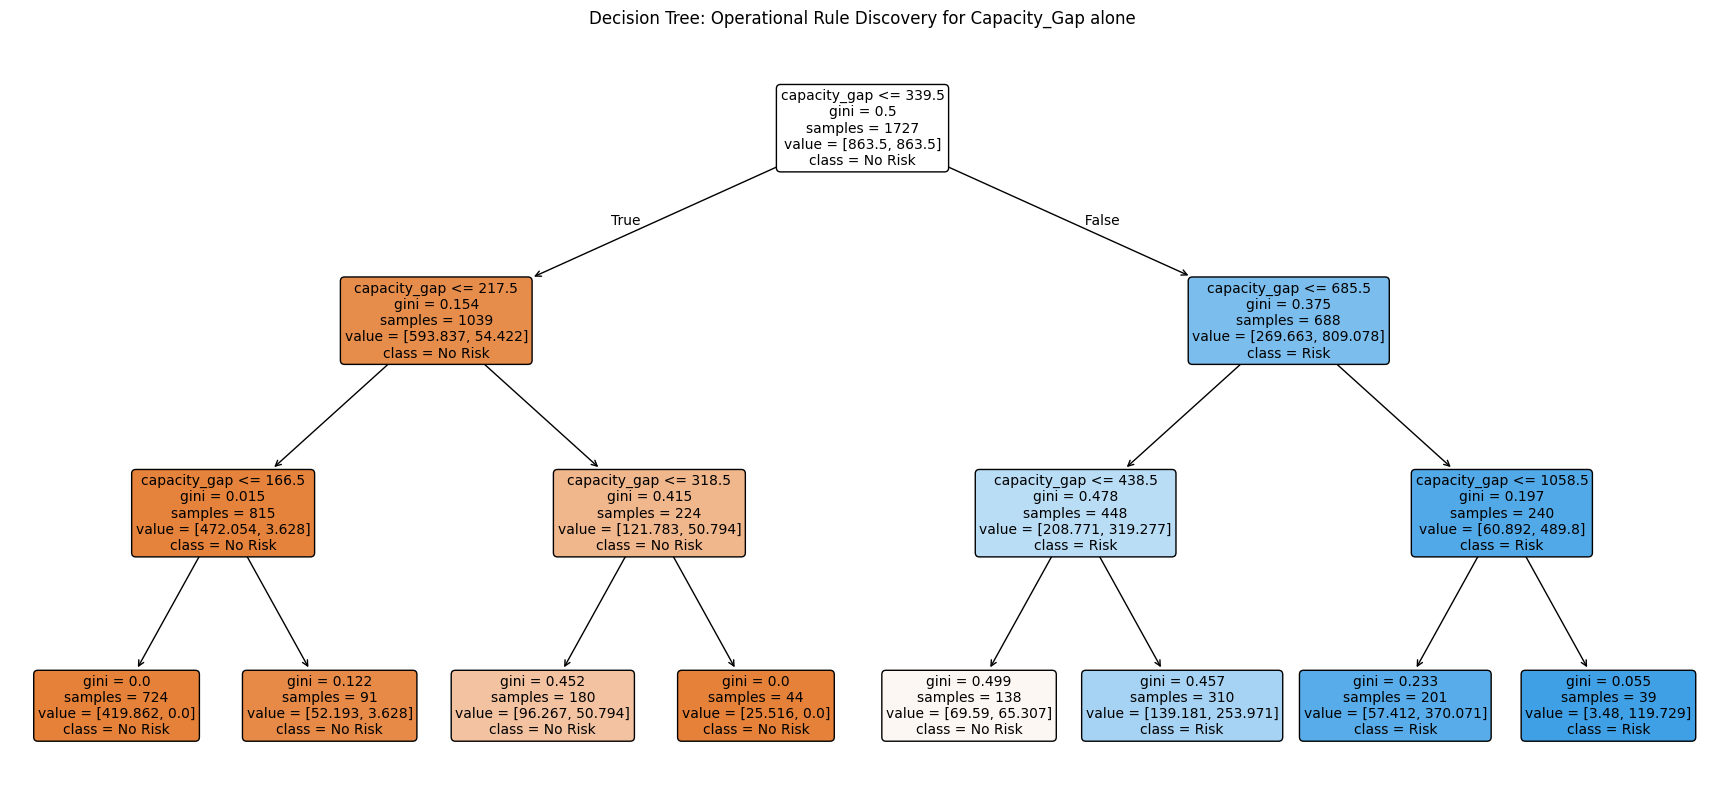

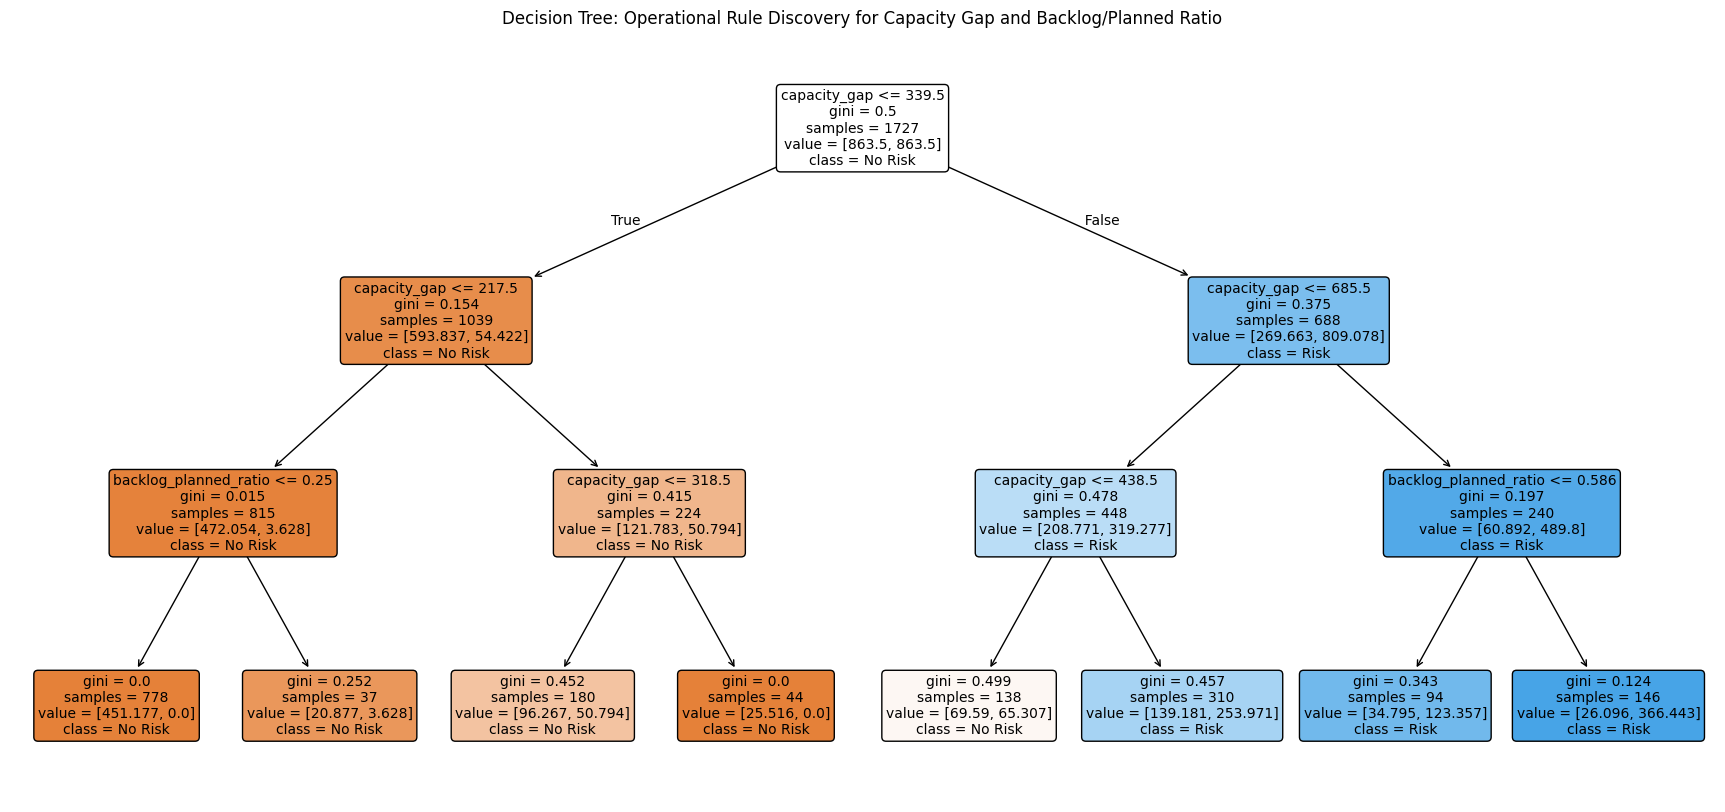

In [ ]:
# Visualize the tree

plt.figure(figsize=(22, 10))

plot_tree(
    cap_gap_dt_model,
    feature_names=cap_gap_feature_cols,
    class_names=["No Risk", "Risk"],
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Decision Tree: Operational Rule Discovery for Capacity_Gap alone")
plt.show()

plt.figure(figsize=(22, 10))

plot_tree(
    cap_gap_bpr_dt_model,
    feature_names=cap_gap_bpr_feature_cols,
    class_names=["No Risk", "Risk"],
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Decision Tree: Operational Rule Discovery for Capacity Gap and Backlog/Planned Ratio")
plt.show()


In [ ]:
rules_cgap_bpr = export_text(
    cap_gap_bpr_dt_model,
    feature_names=cap_gap_bpr_feature_cols
)

print("Rules for Capacity Gap and BPR")
print(rules_cgap_bpr)

Rules for Capacity Gap and BPR
|--- capacity_gap <= 339.50
|   |--- capacity_gap <= 217.50
|   |   |--- backlog_planned_ratio <= 0.25
|   |   |   |--- class: 0
|   |   |--- backlog_planned_ratio >  0.25
|   |   |   |--- class: 0
|   |--- capacity_gap >  217.50
|   |   |--- capacity_gap <= 318.50
|   |   |   |--- class: 0
|   |   |--- capacity_gap >  318.50
|   |   |   |--- class: 0
|--- capacity_gap >  339.50
|   |--- capacity_gap <= 685.50
|   |   |--- capacity_gap <= 438.50
|   |   |   |--- class: 0
|   |   |--- capacity_gap >  438.50
|   |   |   |--- class: 1
|   |--- capacity_gap >  685.50
|   |   |--- backlog_planned_ratio <= 0.59
|   |   |   |--- class: 1
|   |   |--- backlog_planned_ratio >  0.59
|   |   |   |--- class: 1



In [ ]:
risk_probs = cap_gap_bpr_dt_model.predict_proba(
    X_gap_backlog_test
)[:, 1]

results = X_gap_backlog_test.copy()
results["actual"] = y_test
results["predicted"] = cap_gap_bpr_dt_model.predict(
    X_gap_backlog_test
)
results["risk_probability"] = risk_probs

results[
    results["capacity_gap"] > 685.5
].sort_values(
    "risk_probability"
)

,capacity_gap,backlog_planned_ratio,actual,predicted,risk_probability
timestamp,,,,,
2026-04-03 13:00:00,840,0.550000,0,1,0.779990
2026-06-28 12:00:00,820,0.497399,0,1,0.779990
2026-05-28 10:00:00,718,0.465625,1,1,0.779990
2026-05-21 09:00:00,717,0.485294,0,1,0.779990
2026-05-14 12:00:00,746,0.473750,0,1,0.779990
...,...,...,...,...,...
2026-05-30 23:00:00,847,0.874346,0,1,0.933519
2026-06-18 18:00:00,1298,0.822494,1,1,0.933519
2026-04-23 05:00:00,885,0.807910,1,1,0.933519


In [ ]:
# Get predicted probabilities from Capacity Gap + BPR Decision Tree
cap_gap_bpr_risk_probs = cap_gap_bpr_dt_model.predict_proba(
    X_gap_backlog_test
)[:, 1]

# Create results DataFrame
cap_gap_bpr_results = X_gap_backlog_test.copy()

cap_gap_bpr_results["actual"] = y_test
cap_gap_bpr_results["predicted"] = cap_gap_bpr_dt_model.predict(
    X_gap_backlog_test
)
cap_gap_bpr_results["risk_probability"] = cap_gap_bpr_risk_probs


# Focus on the branch where capacity_gap > 685.5
cap_gap_bpr_high_gap = cap_gap_bpr_results[
    cap_gap_bpr_results["capacity_gap"] > 685.5
].copy()


# Separate observations according to the BPR split in the tree
cap_gap_bpr_high_gap["bpr_group"] = np.where(
    cap_gap_bpr_high_gap["backlog_planned_ratio"] <= 0.586,
    "BPR <= 0.586",
    "BPR > 0.586"
)


# Summarize actual vs predicted risk within each branch
cap_gap_bpr_branch_summary = (
    cap_gap_bpr_high_gap
    .groupby("bpr_group")
    .agg(
        observations=("actual", "size"),
        actual_risk_rate=("actual", "mean"),
        predicted_risk_probability=("risk_probability", "mean")
    )
)

print(cap_gap_bpr_branch_summary)

              observations  actual_risk_rate  predicted_risk_probability
bpr_group                                                               
BPR <= 0.586            29          0.275862                    0.779990
BPR > 0.586             39          0.564103                    0.933519


*The one tree shows **capacity_gap** has the greatest importance, and the largest split, but it won't go into too much depth.*

                 Feature  Importance
0           capacity_gap    0.985626
1  backlog_planned_ratio    0.014374 



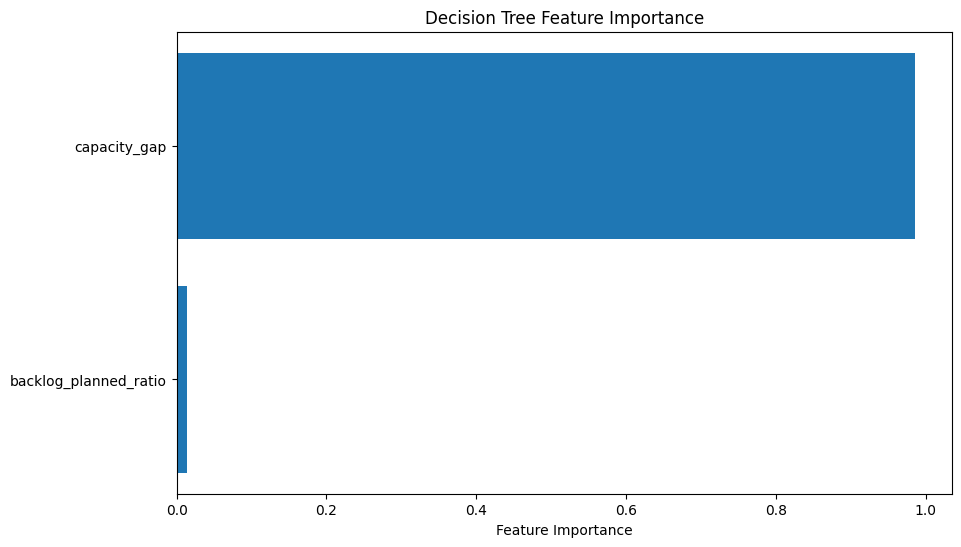

In [ ]:
# Feature importance table for Capacity Gap and BPR

importance_df = pd.DataFrame({
    "Feature": cap_gap_bpr_feature_cols,
    "Importance": cap_gap_bpr_dt_model.feature_importances_
}).sort_values(by="Importance", ascending=False)

print(importance_df,"\n")

plt.figure(figsize=(10, 6))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.gca().invert_yaxis()
plt.xlabel("Feature Importance")
plt.title("Decision Tree Feature Importance")
plt.show()

In [ ]:
# Performing Stratified K-folds on the Decision Tree

# Same folds for both models
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=2
)

fold_results = []
branch_results = []

for fold, (train_idx, val_idx) in enumerate(
    skf.split(X_cap_gap_bpr_scaled, y),
    start=1
):

    # -----------------------------
    # Train / validation data
    # -----------------------------

    X_gap_train = X_cap_gap_feature_cols.iloc[train_idx]
    X_gap_val = X_cap_gap_feature_cols.iloc[val_idx]

    X_bpr_train = X_cap_gap_bpr_feature_cols.iloc[train_idx]
    X_bpr_val = X_cap_gap_bpr_feature_cols.iloc[val_idx]

    y_train = y.iloc[train_idx]
    y_val = y.iloc[val_idx]


    # -----------------------------
    # Capacity Gap Alone model
    # -----------------------------

    cap_gap_dt_model = DecisionTreeClassifier(
        max_depth=4,
        min_samples_leaf=20,
        class_weight="balanced",
        random_state=7
    )

    cap_gap_dt_model.fit(
        X_gap_train,
        y_train
    )


    # -----------------------------
    # Capacity Gap + BPR model
    # -----------------------------

    cap_gap_bpr_dt_model = DecisionTreeClassifier(
        max_depth=4,
        min_samples_leaf=20,
        class_weight="balanced",
        random_state=7
    )

    cap_gap_bpr_dt_model.fit(
        X_bpr_train,
        y_train
    )


    # -----------------------------
    # Validation predictions
    # -----------------------------

    gap_pred = cap_gap_dt_model.predict(
        X_gap_val
    )

    gap_prob = cap_gap_dt_model.predict_proba(
        X_gap_val
    )[:, 1]

    bpr_pred = cap_gap_bpr_dt_model.predict(
        X_bpr_val
    )

    bpr_prob = cap_gap_bpr_dt_model.predict_proba(
        X_bpr_val
    )[:, 1]


    # -----------------------------
    # Overall model performance
    # -----------------------------

    fold_results.append({

        "fold": fold,

        "gap_precision":
            precision_score(y_val, gap_pred),

        "gap_recall":
            recall_score(y_val, gap_pred),

        "gap_f2":
            fbeta_score(
                y_val,
                gap_pred,
                beta=2
            ),

        "gap_auc":
            roc_auc_score(
                y_val,
                gap_prob
            ),

        "gap_bpr_precision":
            precision_score(y_val, bpr_pred),

        "gap_bpr_recall":
            recall_score(y_val, bpr_pred),

        "gap_bpr_f2":
            fbeta_score(
                y_val,
                bpr_pred,
                beta=2
            ),

        "gap_bpr_auc":
            roc_auc_score(
                y_val,
                bpr_prob
            )
    })

In [ ]:
    # -----------------------------
    # Extract tree split thresholds
    # -----------------------------

    tree = cap_gap_bpr_dt_model.tree_

    feature_names = np.array(
        cap_gap_bpr_feature_cols
    )

    # All actual split nodes
    split_nodes = np.where(
        tree.feature >= 0
    )[0]

    split_info = []

    for node in split_nodes:

        feature_name = feature_names[
            tree.feature[node]
        ]

        threshold = tree.threshold[node]

        split_info.append({
            "node": node,
            "feature": feature_name,
            "threshold": threshold
        })


    split_df = pd.DataFrame(split_info)


print(
    export_text(
        cap_gap_bpr_dt_model,
        feature_names=cap_gap_bpr_feature_cols,
        decimals=3
    )
)

|--- capacity_gap <= 429.500
|   |--- capacity_gap <= 244.000
|   |   |--- backlog_planned_ratio <= 0.251
|   |   |   |--- class: 0
|   |   |--- backlog_planned_ratio >  0.251
|   |   |   |--- backlog_planned_ratio <= 0.286
|   |   |   |   |--- class: 0
|   |   |   |--- backlog_planned_ratio >  0.286
|   |   |   |   |--- class: 0
|   |--- capacity_gap >  244.000
|   |   |--- capacity_gap <= 400.500
|   |   |   |--- backlog_planned_ratio <= 0.212
|   |   |   |   |--- class: 0
|   |   |   |--- backlog_planned_ratio >  0.212
|   |   |   |   |--- class: 0
|   |   |--- capacity_gap >  400.500
|   |   |   |--- class: 0
|--- capacity_gap >  429.500
|   |--- capacity_gap <= 681.500
|   |   |--- backlog_planned_ratio <= 0.576
|   |   |   |--- backlog_planned_ratio <= 0.315
|   |   |   |   |--- class: 1
|   |   |   |--- backlog_planned_ratio >  0.315
|   |   |   |   |--- class: 1
|   |   |--- backlog_planned_ratio >  0.576
|   |   |   |--- backlog_planned_ratio <= 0.628
|   |   |   |   |--- clas

*Model using Random Forest, which uses a lot of trees*

In [ ]:
train_idx, test_idx = train_test_split(
    df.index,
    test_size=0.20,
    random_state=7,
    stratify=y
)

# Capacity Gap
X_cap_gap_train = df.loc[
    train_idx,
    cap_gap_feature_cols
]

X_cap_gap_test = df.loc[
    test_idx,
    cap_gap_feature_cols
]


# Capacity Gap + BPR
X_cap_gap_bpr_train = df.loc[
    train_idx,
    cap_gap_bpr_feature_cols
]

X_cap_gap_bpr_test = df.loc[
    test_idx,
    cap_gap_bpr_feature_cols
]


# All 4
X_cap_gap_bpr_wp_packer_train= df.loc[
    train_idx,
    cap_gap_bpr_wp_packer_feature_cols
]

X_cap_gap_bpr_wp_packer_test = df.loc[
    test_idx,
    cap_gap_bpr_wp_packer_feature_cols
]

y_train = y.loc[train_idx]
y_test = y.loc[test_idx]

rf_model_cap_gap = RandomForestClassifier(
    n_estimators=300,
    max_depth=5,
    min_samples_leaf=20,
    random_state=789,
    class_weight="balanced"
)

rf_model_cap_gap.fit(X_cap_gap_train, y_train)

rf_model_cap_gap_bpr = RandomForestClassifier(
    n_estimators=300,
    max_depth=5,
    min_samples_leaf=20,
    random_state=789,
    class_weight="balanced"
)

rf_model_cap_gap_bpr.fit(X_cap_gap_bpr_train, y_train)

rf_model_cap_gap_bpr_wp_packers = RandomForestClassifier(
    n_estimators=300,
    max_depth=5,
    min_samples_leaf=20,
    random_state=789,
    class_weight="balanced"
)

rf_model_cap_gap_bpr_wp_packers.fit(X_cap_gap_bpr_wp_packer_train, y_train)

RandomForestClassifier(class_weight='balanced', max_depth=5,
                       min_samples_leaf=20, n_estimators=300, random_state=789)

*With many trees available, several features get a chance to
contribute more.*

In [ ]:
importance_cap_gap_bpr_df = pd.DataFrame({
    "Feature": cap_gap_bpr_feature_cols,
    "Importance": rf_model_cap_gap_bpr.feature_importances_
}).sort_values(
    by="Importance",
    ascending=False
)

print(importance_cap_gap_bpr_df)
print()

importance_cap_gap_bpr_wp_packer_df = pd.DataFrame({
    "Feature": cap_gap_bpr_wp_packer_feature_cols,
    "Importance": rf_model_cap_gap_bpr_wp_packers.feature_importances_
}).sort_values(
    by="Importance",
    ascending=False
)

print(importance_cap_gap_bpr_wp_packer_df)

                 Feature  Importance
0           capacity_gap    0.527758
1  backlog_planned_ratio    0.472242

                 Feature  Importance
2           capacity_gap    0.501795
3  backlog_planned_ratio    0.281049
0          work_pressure    0.189645
1       packers_assigned    0.027511


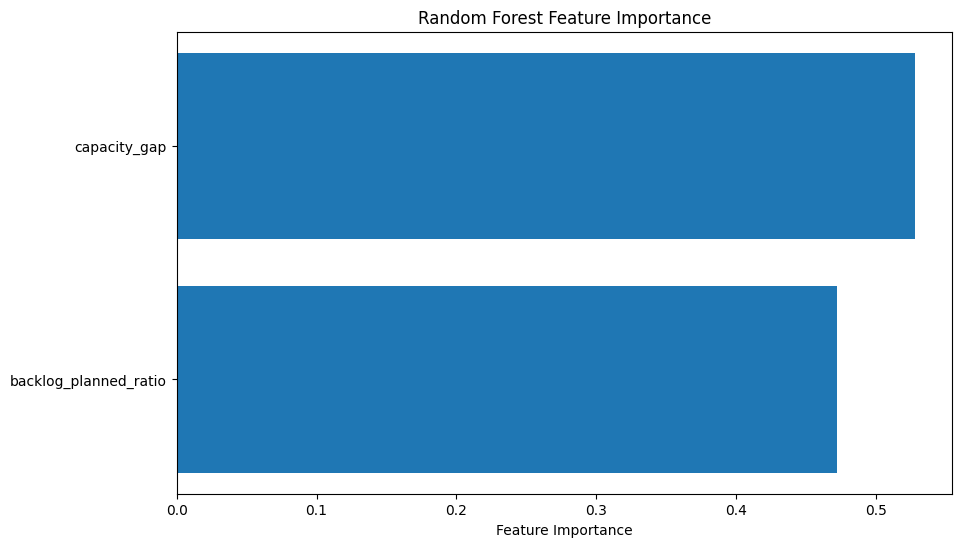

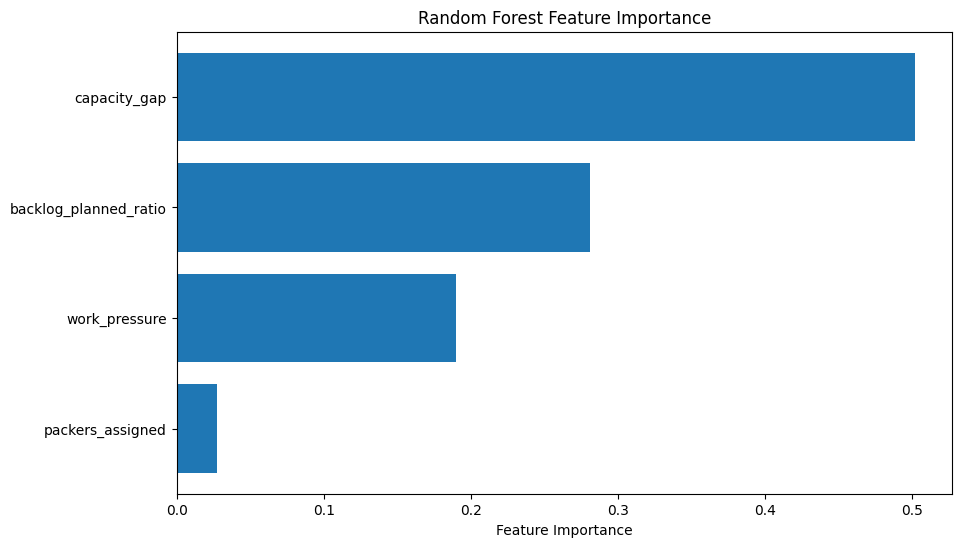

In [ ]:
plt.figure(figsize=(10, 6))

plt.barh(
    importance_cap_gap_bpr_df["Feature"],
    importance_cap_gap_bpr_df["Importance"]
)

plt.gca().invert_yaxis()
plt.xlabel("Feature Importance")
plt.title("Random Forest Feature Importance")
plt.show()

plt.figure(figsize=(10, 6))

plt.barh(
    importance_cap_gap_bpr_wp_packer_df["Feature"],
    importance_cap_gap_bpr_wp_packer_df["Importance"]
)

plt.gca().invert_yaxis()
plt.xlabel("Feature Importance")
plt.title("Random Forest Feature Importance")
plt.show()

*Permutation shows that **capacity_gap** will negatively affect the model the most if removed, and less so with the other features.*

In [ ]:
from sklearn.inspection import permutation_importance

perm_cap_gap_bpr_result = permutation_importance(
    rf_model_cap_gap_bpr,
    X_cap_gap_bpr_test,
    y_test,
    n_repeats=20,
    random_state=56,
    scoring=make_scorer(fbeta_score, beta=2)
)

perm_cap_gap_bpr_result_df = pd.DataFrame({
    "Feature": cap_gap_bpr_feature_cols,
    "Permutation Importance": perm_cap_gap_bpr_result.importances_mean,
    "Std": perm_cap_gap_bpr_result.importances_std
}).sort_values(
    by="Permutation Importance",
    ascending=False
)

print(perm_cap_gap_bpr_result_df)

perm_cap_gap_bpr_wp_packer_result = permutation_importance(
    rf_model_cap_gap_bpr_wp_packers,
    X_cap_gap_bpr_wp_packer_test,
    y_test,
    n_repeats=20,
    random_state=56,
    scoring=make_scorer(fbeta_score, beta=2)
)

perm_cap_gap_bpr_wp_packer_result_df = pd.DataFrame({
    "Feature": cap_gap_bpr_wp_packer_feature_cols,
    "Permutation Importance": perm_cap_gap_bpr_wp_packer_result.importances_mean,
    "Std": perm_cap_gap_bpr_wp_packer_result.importances_std
}).sort_values(
    by="Permutation Importance",
    ascending=False
)

print(perm_cap_gap_bpr_wp_packer_result_df)

                 Feature  Permutation Importance       Std
0           capacity_gap                0.307144  0.050947
1  backlog_planned_ratio                0.244304  0.053627
                 Feature  Permutation Importance       Std
2           capacity_gap                0.291199  0.053546
3  backlog_planned_ratio                0.048700  0.032495
1       packers_assigned                0.008829  0.016769
0          work_pressure               -0.011950  0.016016


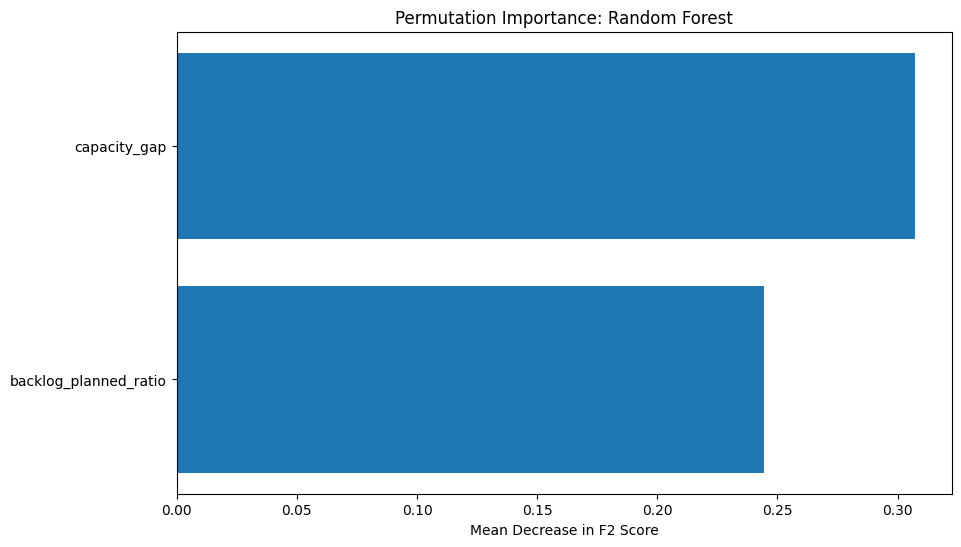

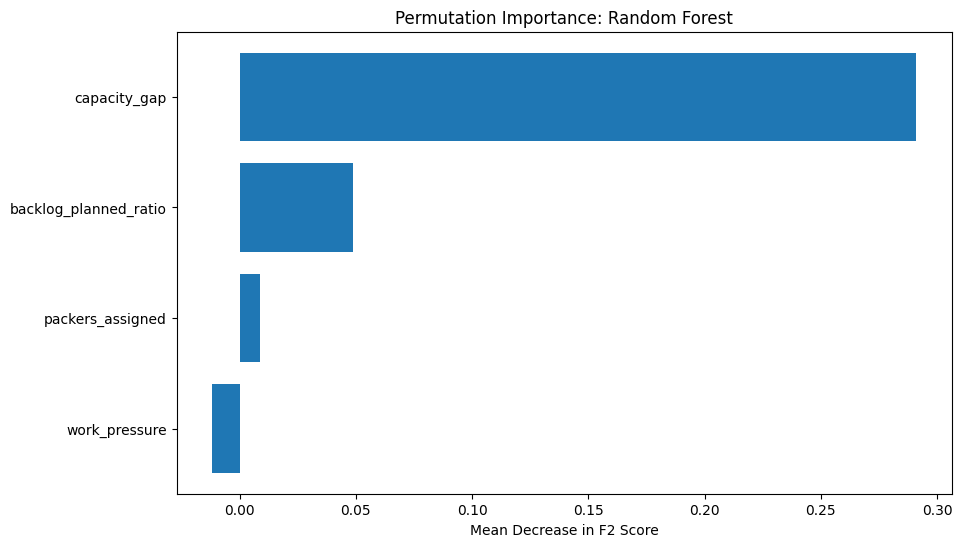

In [ ]:
plt.figure(figsize=(10, 6))

plt.barh(
    perm_cap_gap_bpr_result_df["Feature"],
    perm_cap_gap_bpr_result_df["Permutation Importance"]
)

plt.gca().invert_yaxis()
plt.xlabel("Mean Decrease in F2 Score")
plt.title("Permutation Importance: Random Forest")

plt.figure(figsize=(10, 6))

plt.barh(
    perm_cap_gap_bpr_wp_packer_result_df["Feature"],
    perm_cap_gap_bpr_wp_packer_result_df["Permutation Importance"]
)

plt.gca().invert_yaxis()
plt.xlabel("Mean Decrease in F2 Score")
plt.title("Permutation Importance: Random Forest")
plt.show()


In [ ]:
# ---------------------------------------------------------
# 1. Combine the three feature sets
# ---------------------------------------------------------

rf_feature_sets = {
    "Capacity Gap Alone": cap_gap_feature_cols,
    "Capacity Gap + BPR": cap_gap_bpr_feature_cols,
    "All 4 Features": cap_gap_bpr_wp_packer_feature_cols
}


In [ ]:
# ---------------------------------------------------------
# 2. Same folds for every model
# ---------------------------------------------------------

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=22222
)


# ---------------------------------------------------------
# 3. Store fold-level results
# ---------------------------------------------------------

rf_cv_results = []


In [ ]:
# ---------------------------------------------------------
# 4. Evaluate each feature set
# ---------------------------------------------------------

for model_name, feature_cols in rf_feature_sets.items():

    X = df[feature_cols]

    for fold, (train_idx, val_idx) in enumerate(
        cv.split(X, y),
        start=1
    ):

        X_train = X.iloc[train_idx]
        X_val = X.iloc[val_idx]

        y_train = y.iloc[train_idx]
        y_val = y.iloc[val_idx]


        # ---------------------------------------------
        # Random Forest
        # ---------------------------------------------

        rf_model = RandomForestClassifier(
            n_estimators=300,
            max_depth=8,
            min_samples_leaf=17,
            min_samples_split=2,
            class_weight="balanced",
            random_state=7654,
            n_jobs=-1
        )

        rf_model.fit(
            X_train,
            y_train
        )


        # ---------------------------------------------
        # Predictions
        # ---------------------------------------------

        y_pred = rf_model.predict(X_val)

        y_prob = rf_model.predict_proba(
            X_val
        )[:, 1]


        # ---------------------------------------------
        # Metrics
        # ---------------------------------------------

        precision = precision_score(
            y_val,
            y_pred,
            zero_division=0
        )

        recall = recall_score(
            y_val,
            y_pred,
            zero_division=0
        )

        f2 = fbeta_score(
            y_val,
            y_pred,
            beta=2,
            zero_division=0
        )

        auc = roc_auc_score(
            y_val,
            y_prob
        )


        # ---------------------------------------------
        # Save fold results
        # ---------------------------------------------

        rf_cv_results.append({
            "Model": model_name,
            "Fold": fold,
            "Precision": precision,
            "Recall": recall,
            "F2": f2,
            "ROC_AUC": auc
        })


In [ ]:
# ---------------------------------------------------------
# 5. Convert results to DataFrame
# ---------------------------------------------------------

rf_cv_results_df = pd.DataFrame(
    rf_cv_results
)


# ---------------------------------------------------------
# 6. Summary across the 5 folds
# ---------------------------------------------------------

rf_cv_summary = (
    rf_cv_results_df
    .groupby("Model")
    .agg(
        Precision_Mean=("Precision", "mean"),
        Precision_Std=("Precision", "std"),

        Recall_Mean=("Recall", "mean"),
        Recall_Std=("Recall", "std"),

        F2_Mean=("F2", "mean"),
        F2_Std=("F2", "std"),

        ROC_AUC_Mean=("ROC_AUC", "mean"),
        ROC_AUC_Std=("ROC_AUC", "std")
    )
    .reset_index()
)


# ---------------------------------------------------------
# 7. Display summary
# ---------------------------------------------------------

print(
    rf_cv_summary.round(4).to_string(index=False)
)

             Model  Precision_Mean  Precision_Std  Recall_Mean  Recall_Std  F2_Mean  F2_Std  ROC_AUC_Mean  ROC_AUC_Std
    All 4 Features          0.3673         0.0141       0.7981      0.1098   0.6435  0.0573        0.8821       0.0146
Capacity Gap + BPR          0.3657         0.0167       0.7915      0.1083   0.6397  0.0617        0.8839       0.0151
Capacity Gap Alone          0.3511         0.0196       0.8118      0.0774   0.6408  0.0330        0.8764       0.0164


In [ ]:
# ---------------------------------------------------------
# Paired fold comparison:
# All 4 Features vs Capacity Gap Alone
# ---------------------------------------------------------

# Put each model's F2 score side-by-side by fold
f2_pivot = rf_cv_results_df.pivot(
    index="Fold",
    columns="Model",
    values="F2"
)


# Calculate paired F2 difference
f2_pivot["All4_minus_Gap"] = (
    f2_pivot["All 4 Features"]
    - f2_pivot["Capacity Gap Alone"]
)


# ---------------------------------------------------------
# Display fold-by-fold results
# ---------------------------------------------------------

print("\nFold-by-Fold F2 Comparison")
print("-" * 60)

print(f2_pivot[
        [
            "Capacity Gap Alone",
            "All 4 Features",
            "All4_minus_Gap"
        ]
    ].round(4)
)


# ---------------------------------------------------------
# Summarize paired differences
# ---------------------------------------------------------

f2_diff = f2_pivot["All4_minus_Gap"]

print("\nPaired F2 Difference Summary")
print("-" * 60)
print(f"Mean difference:   {f2_diff.mean():.4f}")
print(f"Median difference: {f2_diff.median():.4f}")
print(f"Std difference:    {f2_diff.std():.4f}")
print(f"Min difference:    {f2_diff.min():.4f}")
print(f"Max difference:    {f2_diff.max():.4f}")

print(
    f"All 4 better:      {(f2_diff > 0).sum()} of {len(f2_diff)} folds"
)
print(
    f"Gap Alone better:  {(f2_diff < 0).sum()} of {len(f2_diff)} folds"
)
print(
    f"Ties:              {(f2_diff == 0).sum()} of {len(f2_diff)} folds"
)


Fold-by-Fold F2 Comparison
------------------------------------------------------------
Model  Capacity Gap Alone  All 4 Features  All4_minus_Gap
Fold                                                     
1                  0.5840          0.5556         -0.0285
2                  0.6634          0.7161          0.0527
3                  0.6438          0.6481          0.0043
4                  0.6477          0.6447         -0.0029
5                  0.6649          0.6528         -0.0121

Paired F2 Difference Summary
------------------------------------------------------------
Mean difference:   0.0027
Median difference: -0.0029
Std difference:    0.0305
Min difference:    -0.0285
Max difference:    0.0527
All 4 better:      2 of 5 folds
Gap Alone better:  3 of 5 folds
Ties:              0 of 5 folds


In [ ]:
from sklearn.model_selection import cross_val_predict

X = df[["capacity_gap"]]
# y was already defined earlier in the notebook
# it is added here for documentation purposes
# y = df["next_hour_backlog_risk"]

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=213243
)

# Each observation gets a probability from a model
# that was not trained on that observation.
oof_prob = cross_val_predict(
    rf_model_cap_gap,
    X,
    y,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

In [ ]:
thresholds = np.arange(0.10, 0.81, 0.01)

threshold_results = []

for threshold in thresholds:

    y_pred = (
        oof_prob >= threshold
    ).astype(int)

    precision = precision_score(
        y,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y,
        y_pred,
        zero_division=0
    )

    f2 = fbeta_score(
        y,
        y_pred,
        beta=2,
        zero_division=0
    )

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F2": f2
    })

threshold_df = pd.DataFrame(
    threshold_results
)

In [ ]:
threshold_df.sort_values(
    "F2",
    ascending=False
).head(15)

best_row = threshold_df.loc[
    threshold_df["F2"].idxmax()
]

print(best_row)


Threshold    0.480000
Precision    0.353887
Recall       0.885906
F2           0.681115
Name: 38, dtype: float64


In [ ]:
threshold_df.loc[
    np.isclose(threshold_df["Threshold"], 0.50)
]

comparison = threshold_df[
    np.isclose(threshold_df["Threshold"], 0.46)
    |
    np.isclose(threshold_df["Threshold"], 0.47)
    |
    np.isclose(threshold_df["Threshold"], 0.48)
    |
    np.isclose(threshold_df["Threshold"], 0.49)
    |
    np.isclose(threshold_df["Threshold"], 0.50)
        |
    np.isclose(threshold_df["Threshold"], 0.51)
        |
    np.isclose(threshold_df["Threshold"], 0.52)
    ]

print(comparison.round(4).to_string(index=False))

 Threshold  Precision  Recall     F2
      0.46     0.3460  0.8893 0.6767
      0.47     0.3501  0.8859 0.6783
      0.48     0.3539  0.8859 0.6811
      0.49     0.3575  0.8758 0.6790
      0.50     0.3586  0.8725 0.6781
      0.51     0.3576  0.8557 0.6693
      0.52     0.3552  0.8356 0.6577


Threshold    0.480000
Precision    0.353887
Recall       0.885906
F2           0.681115
Name: 38, dtype: float64


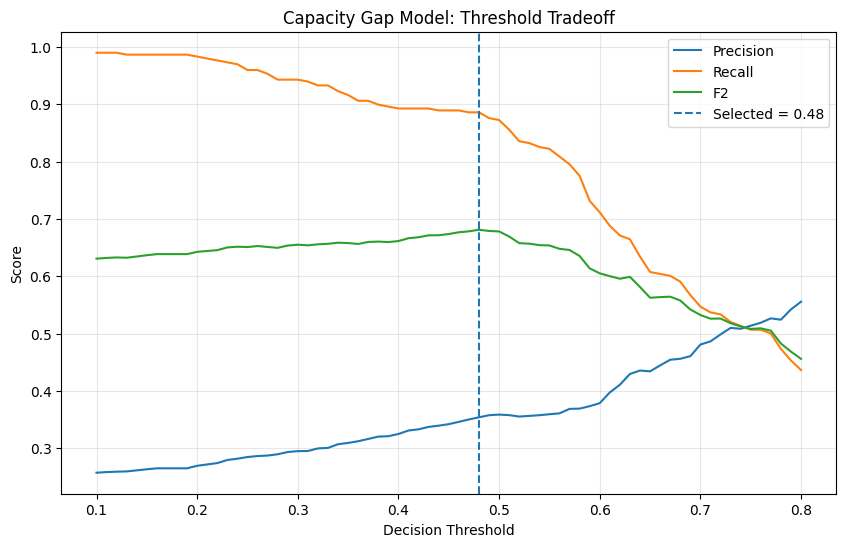

In [ ]:
min_recall = 0.80

eligible_thresholds = threshold_df[
    threshold_df["Recall"] >= min_recall
]

selected_row = eligible_thresholds.loc[
    eligible_thresholds["F2"].idxmax()
]

print(selected_row)

plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F2"],
    label="F2"
)

plt.axvline(
    selected_row["Threshold"],
    linestyle="--",
    label=f"Selected = {selected_row['Threshold']:.2f}"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title(
    "Capacity Gap Model: Threshold Tradeoff"
)

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [ ]:
# Fixed candidate deployment threshold
deployment_threshold = 0.48

# Same CV structure used previously
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=2
)


In [ ]:
fold_results = []

# ---------------------------------------------------------
# Fit and evaluate separately on each fold
# ---------------------------------------------------------

for fold, (train_idx, val_idx) in enumerate(
    cv.split(X, y),
    start=1
):

    X_train = X.iloc[train_idx]
    X_val = X.iloc[val_idx]

    y_train = y.iloc[train_idx]
    y_val = y.iloc[val_idx]


    # ---------------------------------------------
    # Fit Capacity Gap Alone RF
    # ---------------------------------------------

    final_rf_model_cap_gap = RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        min_samples_leaf=17,
        min_samples_split=2,
        class_weight="balanced",
        random_state=7,
        n_jobs=-1
    )

    final_rf_model_cap_gap.fit(
        X_train,
        y_train
    )


    # ---------------------------------------------
    # Predicted probabilities
    # ---------------------------------------------

    val_prob = final_rf_model_cap_gap.predict_proba(
        X_val
    )[:, 1]


    # ---------------------------------------------
    # Apply FIXED 0.48 threshold
    # ---------------------------------------------

    val_pred = (
        val_prob >= deployment_threshold
    ).astype(int)


    # ---------------------------------------------
    # Calculate metrics
    # ---------------------------------------------

    precision = precision_score(
        y_val,
        val_pred,
        zero_division=0
    )

    recall = recall_score(
        y_val,
        val_pred,
        zero_division=0
    )

    f2 = fbeta_score(
        y_val,
        val_pred,
        beta=2,
        zero_division=0
    )


    fold_results.append({
        "Fold": fold,
        "Threshold": deployment_threshold,
        "Precision": precision,
        "Recall": recall,
        "F2": f2
    })


In [ ]:

# ---------------------------------------------------------
# Results DataFrame
# ---------------------------------------------------------

threshold_048_folds = pd.DataFrame(fold_results)

print(threshold_048_folds.round(4).to_string(index=False))

print("\n",threshold_048_folds[
    ["Precision", "Recall", "F2"]
].agg(
    ["mean", "std", "min", "max"]
).round(4))

 Fold  Threshold  Precision  Recall     F2
    1       0.48     0.3381  0.7966 0.6267
    2       0.48     0.3534  0.7833 0.6300
    3       0.48     0.3529  0.9000 0.6870
    4       0.48     0.3431  0.7833 0.6233
    5       0.48     0.3125  0.8475 0.6313

       Precision  Recall      F2
mean     0.3400  0.8221  0.6397
std      0.0167  0.0509  0.0266
min      0.3125  0.7833  0.6233
max      0.3534  0.9000  0.6870


In [ ]:
thresholds = np.arange(
    0.20,
    0.81,
    0.01
)

fold_threshold_results = []


for fold, (train_idx, val_idx) in enumerate(
    cv.split(X, y),
    start=1
):

    X_train = X.iloc[train_idx]
    X_val = X.iloc[val_idx]

    y_train = y.iloc[train_idx]
    y_val = y.iloc[val_idx]


    final_rf_model_cap_gap = RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        min_samples_leaf=17,
        min_samples_split=2,
        class_weight="balanced",
        random_state=7,
        n_jobs=-1
    )


    final_rf_model_cap_gap.fit(
        X_train,
        y_train
    )


    val_prob = final_rf_model_cap_gap.predict_proba(
        X_val
    )[:, 1]


    for threshold in thresholds:

        val_pred = (
            val_prob >= threshold
        ).astype(int)


        fold_threshold_results.append({
            "Fold": fold,
            "Threshold": threshold,

            "Precision": precision_score(
                y_val,
                val_pred,
                zero_division=0
            ),

            "Recall": recall_score(
                y_val,
                val_pred,
                zero_division=0
            ),

            "F2": fbeta_score(
                y_val,
                val_pred,
                beta=2,
                zero_division=0
            )
        })


fold_threshold_df = pd.DataFrame(
    fold_threshold_results
)

In [ ]:
best_threshold_by_fold = (
    fold_threshold_df
    .loc[
        fold_threshold_df
        .groupby("Fold")["F2"]
        .idxmax()
    ]
    .sort_values("Fold")
)


print(
    best_threshold_by_fold
    .round(4)
    .to_string(index=False)
)

print(best_threshold_by_fold[
    "Threshold"
].agg(
    ["mean", "std", "min", "max"]
).round(4))

 Fold  Threshold  Precision  Recall     F2
    1       0.31     0.2969  0.9661 0.6659
    2       0.20     0.3222  0.9667 0.6905
    3       0.43     0.3413  0.9500 0.7002
    4       0.25     0.2984  0.9500 0.6613
    5       0.50     0.3226  0.8475 0.6394
mean    0.3380
std     0.1248
min     0.2000
max     0.5000
Name: Threshold, dtype: float64


In [ ]:
f2_at_048 = (
    fold_threshold_df[
        np.isclose(
            fold_threshold_df["Threshold"],
            0.48
        )
    ][
        ["Fold", "F2"]
    ]
    .rename(
        columns={
            "F2": "F2_at_048"
        }
    )
)


best_f2 = (
    best_threshold_by_fold[
        [
            "Fold",
            "Threshold",
            "F2"
        ]
    ]
    .rename(
        columns={
            "Threshold": "Best_Threshold",
            "F2": "Best_F2"
        }
    )
)


threshold_stability = (
    f2_at_048
    .merge(
        best_f2,
        on="Fold"
    )
)


threshold_stability[
    "F2_Loss_at_048"
] = (
    threshold_stability["Best_F2"]
    - threshold_stability["F2_at_048"]
)


print(
    threshold_stability
    .round(4)
    .to_string(index=False)
)

 Fold  F2_at_048  Best_Threshold  Best_F2  F2_Loss_at_048
    1     0.6267            0.31   0.6659          0.0392
    2     0.6300            0.20   0.6905          0.0604
    3     0.6870            0.43   0.7002          0.0132
    4     0.6233            0.25   0.6613          0.0379
    5     0.6313            0.50   0.6394          0.0081


In [ ]:
threshold_summary = (
    fold_threshold_df
    .groupby("Threshold")
    .agg(
        Precision_Mean=("Precision", "mean"),
        Precision_SD=("Precision", "std"),
        Recall_Mean=("Recall", "mean"),
        Recall_SD=("Recall", "std"),
        F2_Mean=("F2", "mean"),
        F2_SD=("F2", "std")
    )
    .reset_index()
)

print(
    threshold_summary
    .sort_values("F2_Mean", ascending=False)
    .head(15)
    .round(4)
    .to_string(index=False)
)

 Threshold  Precision_Mean  Precision_SD  Recall_Mean  Recall_SD  F2_Mean  F2_SD
      0.41          0.3283        0.0250       0.8893     0.0384   0.6616 0.0233
      0.39          0.3235        0.0234       0.8960     0.0341   0.6607 0.0208
      0.40          0.3244        0.0234       0.8926     0.0346   0.6602 0.0237
      0.38          0.3221        0.0212       0.8960     0.0341   0.6596 0.0202
      0.37          0.3207        0.0194       0.8960     0.0341   0.6586 0.0199
      0.36          0.3203        0.0190       0.8960     0.0341   0.6583 0.0200
      0.42          0.3272        0.0243       0.8759     0.0493   0.6547 0.0279
      0.35          0.3147        0.0167       0.8960     0.0341   0.6538 0.0211
      0.33          0.3098        0.0156       0.9060     0.0303   0.6538 0.0182
      0.34          0.3111        0.0158       0.9027     0.0299   0.6535 0.0198
      0.32          0.3077        0.0142       0.9094     0.0324   0.6533 0.0194
      0.29          0.3001  

In [ ]:
threshold_summary["F2_Mean_Minus_SD"] = (
    threshold_summary["F2_Mean"]
    - threshold_summary["F2_SD"]
)

print(threshold_summary[
    [
        "Threshold",
        "F2_Mean",
        "F2_SD",
        "F2_Mean_Minus_SD",
        "Recall_Mean",
        "Recall_SD",
        "Precision_Mean"
    ]
].sort_values(
    "F2_Mean_Minus_SD",
    ascending=False
).head(15).round(4))

    Threshold  F2_Mean   F2_SD  F2_Mean_Minus_SD  Recall_Mean  Recall_SD  \
19       0.39   0.6607  0.0208            0.6399       0.8960     0.0341   
18       0.38   0.6596  0.0202            0.6394       0.8960     0.0341   
17       0.37   0.6586  0.0199            0.6387       0.8960     0.0341   
16       0.36   0.6583  0.0200            0.6383       0.8960     0.0341   
21       0.41   0.6616  0.0233            0.6383       0.8893     0.0384   
9        0.29   0.6527  0.0159            0.6369       0.9263     0.0383   
20       0.40   0.6602  0.0237            0.6364       0.8926     0.0346   
13       0.33   0.6538  0.0182            0.6356       0.9060     0.0303   
12       0.32   0.6533  0.0194            0.6339       0.9094     0.0324   
14       0.34   0.6535  0.0198            0.6338       0.9027     0.0299   
8        0.28   0.6485  0.0148            0.6337       0.9263     0.0383   
15       0.35   0.6538  0.0211            0.6327       0.8960     0.0341   
4        0.2

In [ ]:
candidate_region = (
    threshold_summary[
        threshold_summary["Threshold"]
        .between(0.25, 0.45)
    ][
        [
            "Threshold",
            "Precision_Mean",
            "Precision_SD",
            "Recall_Mean",
            "Recall_SD",
            "F2_Mean",
            "F2_SD"
        ]
    ]
)

print(
    candidate_region
    .round(4)
    .to_string(index=False)
)

 Threshold  Precision_Mean  Precision_SD  Recall_Mean  Recall_SD  F2_Mean  F2_SD
      0.25          0.2916        0.0173       0.9363     0.0362   0.6483 0.0161
      0.26          0.2931        0.0170       0.9263     0.0383   0.6458 0.0140
      0.27          0.2944        0.0182       0.9263     0.0383   0.6470 0.0154
      0.28          0.2959        0.0175       0.9263     0.0383   0.6485 0.0148
      0.29          0.3001        0.0152       0.9263     0.0383   0.6527 0.0159
      0.30          0.3000        0.0158       0.9162     0.0408   0.6487 0.0199
      0.31          0.3042        0.0152       0.9162     0.0408   0.6527 0.0205
      0.32          0.3077        0.0142       0.9094     0.0324   0.6533 0.0194
      0.33          0.3098        0.0156       0.9060     0.0303   0.6538 0.0182
      0.34          0.3111        0.0158       0.9027     0.0299   0.6535 0.0198
      0.35          0.3147        0.0167       0.8960     0.0341   0.6538 0.0211
      0.36          0.3203  

In [ ]:
# Candidate thresholds to compare
candidate_thresholds = [0.33, 0.34, 0.39, 0.41]


# Extract results for those thresholds
candidate_fold_results = fold_threshold_df[
    fold_threshold_df["Threshold"].apply(
        lambda x: any(
            np.isclose(x, t)
            for t in candidate_thresholds
        )
    )
].copy()


# Sort by threshold, then fold
candidate_fold_results = (
    candidate_fold_results
    .sort_values(
        ["Threshold", "Fold"]
    )
)


print(
    candidate_fold_results
    .round(4)
    .to_string(index=False)
)

 Fold  Threshold  Precision  Recall     F2
    1       0.33     0.3000  0.9153 0.6490
    2       0.33     0.3291  0.8667 0.6533
    3       0.33     0.3220  0.9500 0.6835
    4       0.33     0.3068  0.9000 0.6490
    5       0.33     0.2912  0.8983 0.6340
    1       0.34     0.2978  0.8983 0.6401
    2       0.34     0.3291  0.8667 0.6533
    3       0.34     0.3257  0.9500 0.6867
    4       0.34     0.3086  0.9000 0.6506
    5       0.34     0.2944  0.8983 0.6370
    1       0.39     0.3064  0.8983 0.6479
    2       0.39     0.3537  0.8667 0.6718
    3       0.39     0.3295  0.9500 0.6901
    4       0.39     0.3333  0.8667 0.6566
    5       0.39     0.2944  0.8983 0.6370
    1       0.41     0.3064  0.8983 0.6479
    2       0.41     0.3617  0.8500 0.6693
    3       0.41     0.3373  0.9500 0.6968
    4       0.41     0.3355  0.8667 0.6582
    5       0.41     0.3006  0.8814 0.6357


In [ ]:
# Fixed candidate deployment threshold
deployment_threshold = 0.39

# 5-fold CV repeated 5 times = 25 validation folds
cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=5,
    random_state=2
)

# Store results
results = []
prediction_records = []

# Run repeated cross-validation
for split_num, (train_idx, val_idx) in enumerate(
    cv.split(X, y),
    start=1
):

    # Repeat and fold numbers
    repeat = ((split_num - 1) // 5) + 1
    fold = ((split_num - 1) % 5) + 1


    X_train = X.iloc[train_idx]
    X_val = X.iloc[val_idx]

    y_train = y.iloc[train_idx]
    y_val = y.iloc[val_idx]

    # Same Capacity-Gap-only Random Forest
    final_rf_model_cap_gap = RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        min_samples_leaf=17,
        min_samples_split=2,
        class_weight="balanced",
        random_state=7,
        n_jobs=-1
    )

    final_rf_model_cap_gap.fit(X_train, y_train)

    # Predicted probabilities
    val_prob = final_rf_model_cap_gap.predict_proba(X_val)[:, 1]

    # Apply FIXED 0.39 threshold
    val_pred = (val_prob >= deployment_threshold).astype(int)

    # Metrics
    precision = precision_score(
        y_val,
        val_pred,
        zero_division=0
    )

    recall = recall_score(
        y_val,
        val_pred,
        zero_division=0
    )

    f2 = fbeta_score(
        y_val,
        val_pred,
        beta=2,
        zero_division=0
    )

    tn, fp, fn, tp = confusion_matrix(y_val, val_pred).ravel()

    results.append({
        "Repeat": repeat,
        "Fold": fold,
        "Threshold": deployment_threshold,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Precision": precision,
        "Recall": recall,
        "F2": f2
        })

    # Store each validation observation
    fold_predictions = pd.DataFrame({
        "Repeat": repeat,
        "Fold": fold,
        "Row_Index": y_val.index,
        "Actual": y_val.values,
        "Predicted": val_pred,
        "Probability": val_prob,
        "capacity_gap": X_val["capacity_gap"].values
        })

    prediction_records.append(
        fold_predictions
    )

all_predictions = pd.concat(prediction_records,ignore_index=True)

conditions = [
    (all_predictions["Actual"] == 1) &
    (all_predictions["Predicted"] == 1),

    (all_predictions["Actual"] == 1) &
    (all_predictions["Predicted"] == 0),

    (all_predictions["Actual"] == 0) &
    (all_predictions["Predicted"] == 1),

    (all_predictions["Actual"] == 0) &
    (all_predictions["Predicted"] == 0)
]

labels = [
    "TP",
    "FN",
    "FP",
    "TN"
]

all_predictions["Outcome"] = np.select(
    conditions,
    labels,
    default="Unknown"
)

# Convert to DataFrame
repeated_cv_results = pd.DataFrame(results)

# Display all 25 validation results
print("\nAll 25 Validation Folds\n")

print(
    repeated_cv_results
    .round(4)
    .to_string(index=False)
)

worst_recall = (
    repeated_cv_results
    .sort_values("Recall")
    [
        [
            "Repeat",
            "Fold",
            "TP",
            "FN",
            "FP",
            "TN",
            "Precision",
            "Recall",
            "F2"
        ]
    ]
)

print(worst_recall.head(10).round(4).to_string(index=False))



All 25 Validation Folds

 Repeat  Fold  Threshold  TN  FP  FN  TP  Precision  Recall     F2
      1     1       0.39 253 120   6  53     0.3064  0.8983 0.6479
      1     2       0.39 277  95   8  52     0.3537  0.8667 0.6718
      1     3       0.39 256 116   3  57     0.3295  0.9500 0.6901
      1     4       0.39 268 104   8  52     0.3333  0.8667 0.6566
      1     5       0.39 245 127   6  53     0.2944  0.8983 0.6370
      2     1       0.39 271 102  10  49     0.3245  0.8305 0.6331
      2     2       0.39 232 140   3  57     0.2893  0.9500 0.6522
      2     3       0.39 265 107   2  58     0.3515  0.9667 0.7160
      2     4       0.39 262 110   5  55     0.3333  0.9167 0.6790
      2     5       0.39 270 102   8  51     0.3333  0.8644 0.6555
      3     1       0.39 266 107  10  49     0.3141  0.8305 0.6250
      3     2       0.39 271 101  13  47     0.3176  0.7833 0.6057
      3     3       0.39 234 138   3  57     0.2923  0.9500 0.6552
      3     4       0.39 266 106   9

In [ ]:
positive_cases = all_predictions[
    all_predictions["Outcome"].isin(
        ["TP", "FN"]
    )
]

gap_comparison = (
    positive_cases
    .groupby("Outcome")[
        ["capacity_gap", "Probability"]
    ]
    .agg([
        "count",
        "mean",
        "median",
        "std",
        "min",
        "max"
    ])
)

print(gap_comparison.round(4))

false_negatives = (
    all_predictions[
        all_predictions["Outcome"] == "FN"
    ]
    .sort_values("Probability", ascending=False)
)

print(
    false_negatives
    .head(25)
    .round(4)
    .to_string(index=False)
)

        capacity_gap                                       Probability  \
               count      mean median       std  min   max       count   
Outcome                                                                  
FN               158  353.5570  330.5  114.6911  167   640         158   
TP              1332  779.2665  757.0  261.4854  253  1647        1332   

                                                 
           mean  median     std     min     max  
Outcome                                          
FN       0.2008  0.2082  0.1137  0.0000  0.3876  
TP       0.7496  0.7734  0.1643  0.3909  0.9865  
 Repeat  Fold           Row_Index  Actual  Predicted  Probability  capacity_gap Outcome
      2     1 2026-04-25 17:00:00       1          0       0.3876           542      FN
      4     1 2026-04-01 19:00:00       1          0       0.3855           395      FN
      4     1 2026-06-11 20:00:00       1          0       0.3831           313      FN
      2     4 2026-06-24 23

In [ ]:
fn_frequency = (
    all_predictions[
        all_predictions["Outcome"] == "FN"
    ]
    .groupby("Row_Index")
    .size()
    .reset_index(name="FN_Count")
    .sort_values(
        "FN_Count",
        ascending=False
    )
)

print(fn_frequency.head(20).to_string(index=False))

          Row_Index  FN_Count
2026-04-01 14:00:00         5
2026-04-01 23:00:00         5
2026-04-02 19:00:00         5
2026-04-10 10:00:00         5
2026-04-10 04:00:00         5
2026-04-19 09:00:00         5
2026-04-23 04:00:00         5
2026-04-11 23:00:00         5
2026-04-18 15:00:00         5
2026-06-11 11:00:00         5
2026-05-29 22:00:00         5
2026-05-20 15:00:00         5
2026-05-20 03:00:00         5
2026-05-02 21:00:00         5
2026-05-08 02:00:00         5
2026-05-07 02:00:00         5
2026-06-09 15:00:00         5
2026-06-11 00:00:00         5
2026-06-24 16:00:00         5
2026-06-25 19:00:00         5


In [ ]:
# Overall summary across all 25 validation folds
overall_summary = (
    repeated_cv_results[
        ["Precision", "Recall", "F2"]
    ]
    .agg([
        "mean",
        "std",
        "min",
        "max"
    ])
)

print("\nOverall 5x5 Repeated CV Summary\n")

print(overall_summary.round(4))


Overall 5x5 Repeated CV Summary

      Precision  Recall      F2
mean     0.3251  0.8939  0.6613
std      0.0204  0.0529  0.0321
min      0.2893  0.7833  0.5985
max      0.3671  0.9831  0.7360


In [ ]:
# Mean, SD, min, max and range
stability_summary = pd.DataFrame({
    "Mean": repeated_cv_results[
        ["Precision", "Recall", "F2"]
    ].mean(),

    "SD": repeated_cv_results[
        ["Precision", "Recall", "F2"]
    ].std(),

    "Min": repeated_cv_results[
        ["Precision", "Recall", "F2"]
    ].min(),

    "Max": repeated_cv_results[
        ["Precision", "Recall", "F2"]
    ].max()
})

stability_summary["Range"] = (
    stability_summary["Max"]
    - stability_summary["Min"]
)

print("\nThreshold 0.39 Stability Summary\n")

print(stability_summary.round(4))


Threshold 0.39 Stability Summary

             Mean      SD     Min     Max   Range
Precision  0.3251  0.0204  0.2893  0.3671  0.0777
Recall     0.8939  0.0529  0.7833  0.9831  0.1997
F2         0.6613  0.0321  0.5985  0.7360  0.1375


In [ ]:
# Summary within each of the 5 repeats
repeat_summary = (
    repeated_cv_results
    .groupby("Repeat")
    .agg(
        Precision_Mean=("Precision", "mean"),
        Precision_SD=("Precision", "std"),

        Recall_Mean=("Recall", "mean"),
        Recall_SD=("Recall", "std"),

        F2_Mean=("F2", "mean"),
        F2_SD=("F2", "std")
    )
    .reset_index()
)


print("\nSummary by Repeat\n")

print(
    repeat_summary
    .round(4)
    .to_string(index=False)
)


Summary by Repeat

 Repeat  Precision_Mean  Precision_SD  Recall_Mean  Recall_SD  F2_Mean  F2_SD
      1          0.3235        0.0234       0.8960     0.0341   0.6607 0.0208
      2          0.3264        0.0229       0.9056     0.0574   0.6672 0.0318
      3          0.3232        0.0274       0.8794     0.0840   0.6528 0.0501
      4          0.3286        0.0168       0.8959     0.0363   0.6655 0.0233
      5          0.3240        0.0190       0.8923     0.0596   0.6604 0.0393


In [ ]:
# Using the already-fitted/frozen model as using only the
# capacity gap variable

gap_grid = np.arange(
    df["capacity_gap"].min(),
    df["capacity_gap"].max() + 1,
    1
)

X_grid = pd.DataFrame({
    "capacity_gap": gap_grid
})

risk_grid = final_rf_model_cap_gap.predict_proba(X_grid)[:, 1]

monotonic_check = pd.DataFrame({
    "capacity_gap": gap_grid,
    "predicted_risk": risk_grid
})

# Change in risk as capacity gap increases
monotonic_check["risk_change"] = (
    monotonic_check["predicted_risk"].diff()
)

# If gap increases, risk should NOT decrease.
monotonic_check["violation"] = (
    monotonic_check["risk_change"] < -1e-10
)

print(
    "Number of monotonicity violations:",
    monotonic_check["violation"].sum()
)

print(
    "Largest unexpected risk decrease:",
    monotonic_check["risk_change"].min()
)

Number of monotonicity violations: 295
Largest unexpected risk decrease: -0.13503912332420015


In [ ]:
def simulate_adding_packers(
    row,
    model,
    max_added_packers=10
):
    results = []

    available_work = row["available_work"]
    current_packers = row["packers_assigned"]
    units_per_packer = row["avg_units_per_packer"]

    for added in range(max_added_packers + 1):

        new_packers = current_packers + added

        new_capacity = (
            new_packers * units_per_packer
        )

        new_capacity_gap = max(
            0,
            available_work - new_capacity
        )

        X_cf = pd.DataFrame({
            "capacity_gap": [new_capacity_gap]
        })

        predicted_risk = model.predict_proba(
            X_cf
        )[0, 1]

        results.append({
            "added_packers": added,
            "new_packers": new_packers,
            "new_capacity": new_capacity,
            "new_capacity_gap": new_capacity_gap,
            "predicted_risk": predicted_risk
        })

    return pd.DataFrame(results)

In [ ]:
row = df.iloc[100]

simulation = simulate_adding_packers(
    row=row,
    model=final_rf_model_cap_gap,
    max_added_packers=10
)

print(
    simulation
    .round(4)
    .to_string(index=False)
)

 added_packers  new_packers  new_capacity  new_capacity_gap  predicted_risk
             0           15          1305               178           0.162
             1           16          1392                91           0.000
             2           17          1479                 4           0.000
             3           18          1566                 0           0.000
             4           19          1653                 0           0.000
             5           20          1740                 0           0.000
             6           21          1827                 0           0.000
             7           22          1914                 0           0.000
             8           23          2001                 0           0.000
             9           24          2088                 0           0.000
            10           25          2175                 0           0.000


In [ ]:
simulation["risk_change"] = (
    simulation["predicted_risk"].diff()
)

simulation["violation"] = (
    simulation["risk_change"] > 1e-10
)

print(simulation.round(4))

print(
    "\nViolations:",
    simulation["violation"].sum()
)

    added_packers  new_packers  new_capacity  new_capacity_gap  \
0               0           15          1305               178   
1               1           16          1392                91   
2               2           17          1479                 4   
3               3           18          1566                 0   
4               4           19          1653                 0   
5               5           20          1740                 0   
6               6           21          1827                 0   
7               7           22          1914                 0   
8               8           23          2001                 0   
9               9           24          2088                 0   
10             10           25          2175                 0   

    predicted_risk  risk_change  violation  
0            0.162          NaN      False  
1            0.000       -0.162      False  
2            0.000        0.000      False  
3            0.000        0

In [ ]:
# ---------------------------------------------------------
# Identify currently high-risk observations
# ---------------------------------------------------------

df_check = df.copy()

# Current predicted risk using capacity_gap
df_check["current_risk"] = (
    final_rf_model_cap_gap
    .predict_proba(
        df_check[["capacity_gap"]]
    )[:, 1]
)

# Apply frozen 0.39 threshold
high_risk_rows = df_check[
    df_check["current_risk"] >= 0.39
].copy()


print(
    "Total observations:",
    len(df_check)
)

print(
    "High-risk observations:",
    len(high_risk_rows)
)

print(
    "High-risk percentage:",
    f"{len(high_risk_rows) / len(df_check):.2%}"
)

Total observations: 2159
High-risk observations: 799
High-risk percentage: 37.01%


In [ ]:
# ---------------------------------------------------------
# Build all counterfactual staffing scenarios
# ---------------------------------------------------------

simulation_rows = []

for idx, row in high_risk_rows.iterrows():

    for added in range(11):

        new_packers = (
            row["packers_assigned"] + added
        )

        new_capacity = (
            new_packers *
            row["avg_units_per_packer"]
        )

        new_capacity_gap = max(
            0,
            row["available_work"] - new_capacity
        )

        simulation_rows.append({
            "row_index": idx,
            "added_packers": added,
            "new_packers": new_packers,
            "new_capacity": new_capacity,
            "new_capacity_gap": new_capacity_gap
        })


counterfactuals = pd.DataFrame(
    simulation_rows
)


# ---------------------------------------------------------
# Score ALL scenarios at once
# ---------------------------------------------------------

X_counterfactual = (
    counterfactuals[
        ["new_capacity_gap"]
    ]
    .rename(
        columns={
            "new_capacity_gap": "capacity_gap"
        }
    )
)


In [ ]:
counterfactuals["predicted_risk"] = (
    final_rf_model_cap_gap
    .predict_proba(X_counterfactual)[:, 1]
)

counterfactuals = (
    counterfactuals
    .sort_values(
        ["row_index", "added_packers"]
    )
    .reset_index(drop=True)
)

counterfactuals["risk_change"] = (
    counterfactuals
    .groupby("row_index")[
        "predicted_risk"
    ]
    .diff()
)

In [ ]:
total_scenarios = len(counterfactuals)

total_transitions = (
    counterfactuals["risk_change"]
    .notna()
    .sum()
)

tolerance = 1e-10

counterfactuals["violation"] = (
    counterfactuals["risk_change"] > tolerance
)

total_violations = (
    counterfactuals["violation"]
    .sum()
)

rows_with_violations = (
    counterfactuals.loc[
        counterfactuals["violation"],
        "row_index"
    ]
    .nunique()
)


print(
    "High-risk observations tested:",
    len(high_risk_rows)
)

print(
    "Counterfactual scenarios:",
    total_scenarios
)

print(
    "Staffing transitions tested:",
    total_transitions
)

print(
    "Monotonicity violations:",
    total_violations
)

print(
    "Observations with at least one violation:",
    rows_with_violations
)

violation_rate = (
    total_violations /
    total_transitions
)

print(
    f"Violation rate: "
    f"{violation_rate:.2%}"
)

High-risk observations tested: 799
Counterfactual scenarios: 8789
Staffing transitions tested: 7990
Monotonicity violations: 1067
Observations with at least one violation: 580
Violation rate: 13.35%


In [ ]:
violation_details = (
    counterfactuals[
        counterfactuals["violation"]
    ]
    .copy()
    .sort_values(
        "risk_change",
        ascending=False
    )
)


print(
    violation_details[
        [
            "row_index",
            "added_packers",
            "new_capacity_gap",
            "predicted_risk",
            "risk_change"
        ]
    ]
    .head(30)
    .round(4)
    .to_string(index=False)
)

if len(violation_details) > 0:

    print("\nViolation magnitude:")

    print(
        violation_details["risk_change"]
        .describe()
        .round(4)
    )

          row_index  added_packers  new_capacity_gap  predicted_risk  risk_change
2026-06-19 06:00:00              6               447          0.6713       0.3226
2026-04-03 17:00:00              8               253          0.4681       0.3169
2026-04-23 05:00:00              8               253          0.4681       0.3169
2026-06-11 19:00:00              6               253          0.4681       0.3163
2026-04-22 04:00:00              4               253          0.4681       0.3161
2026-06-28 05:00:00              8               253          0.4681       0.3105
2026-05-28 00:00:00              6               253          0.4681       0.3048
2026-06-25 20:00:00              8               257          0.4555       0.3044
2026-04-15 06:00:00              3               254          0.4553       0.3041
2026-04-03 10:00:00              8               255          0.4550       0.3038
2026-05-06 05:00:00              3               255          0.4550       0.3038
2026-06-28 04:00

In [ ]:
violation_check = counterfactuals.loc[
    counterfactuals["violation"],
    "risk_change"
]

print(
    violation_check.describe(
        percentiles=[
            .10, .25, .50, .75,
            .90, .95, .99
        ]
    ).round(4)
)

thresholds = [
    0.001,   # 0.1 percentage point
    0.005,   # 0.5 percentage point
    0.01,    # 1 percentage point
    0.02,    # 2 percentage points
    0.05,    # 5 percentage points
    0.10     # 10 percentage points
]

for t in thresholds:

    count = (
        counterfactuals["risk_change"] > t
    ).sum()

    rate = count / total_transitions

    affected_rows = (
        counterfactuals.loc[
            counterfactuals["risk_change"] > t,
            "row_index"
        ]
        .nunique()
    )

    print(
        f">{t:.3f}: "
        f"{count:4d} violations | "
        f"{rate:6.2%} of transitions | "
        f"{affected_rows:3d} rows"
    )

count    1067.0000
mean        0.0969
std         0.0821
min         0.0002
10%         0.0093
25%         0.0244
50%         0.0819
75%         0.1410
90%         0.2233
95%         0.2866
99%         0.3036
max         0.3226
Name: risk_change, dtype: float64
>0.001: 1051 violations | 13.15% of transitions | 575 rows
>0.005: 1011 violations | 12.65% of transitions | 566 rows
>0.010:  959 violations | 12.00% of transitions | 559 rows
>0.020:  842 violations | 10.54% of transitions | 531 rows
>0.050:  664 violations |  8.31% of transitions | 471 rows
>0.100:  459 violations |  5.74% of transitions | 379 rows


In [ ]:
gap_increases = (
    counterfactuals
    .groupby("row_index")[
        "new_capacity_gap"
    ]
    .diff()
)

print(
    "Cases where adding a packer increased capacity gap:",
    (gap_increases > 0).sum()
)

Cases where adding a packer increased capacity gap: 0


In [ ]:
counterfactuals["previous_risk"] = (
    counterfactuals
    .groupby("row_index")["predicted_risk"]
    .shift(1)
)

counterfactuals["upward_threshold_crossing"] = (
    (counterfactuals["previous_risk"] < 0.39) &
    (counterfactuals["predicted_risk"] >= 0.39)
)

upward_crossings = (
    counterfactuals["upward_threshold_crossing"]
    .sum()
)

affected_rows = (
    counterfactuals.loc[
        counterfactuals["upward_threshold_crossing"],
        "row_index"
    ]
    .nunique()
)

print(
    "Upward crossings of 0.39:",
    upward_crossings
)

print(
    "Rows with upward crossing:",
    affected_rows
)

Upward crossings of 0.39: 180
Rows with upward crossing: 174
